In [47]:
import os
from pathlib import Path


os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")
os.environ.setdefault("NUMBA_NUM_THREADS", "1")

SEED = 0


RUN_DIR = Path.cwd()
FIG_DIR = RUN_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR = RUN_DIR / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


import scanpy as sc
import scanpy.external as sce

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.io import mmread
from scipy.sparse import csr_matrix, issparse
from sklearn.preprocessing import StandardScaler

import matplotlib as mpl
mpl.rcParams["font.family"] = "Arial"
mpl.rcParams["font.size"] = 10


np.random.seed(SEED)
sc.settings.seed = SEED
sc.settings.n_jobs = 1
sc.settings.verbosity = 0


In [48]:
meta_path = Path.cwd() / "samples-new.csv"
meta_df = pd.read_csv(meta_path)
meta_df.set_index("GSM", inplace=True)

required_corrected_samples = {"GSM6544087", "GSM6544088"}
missing_corrected = required_corrected_samples.difference(meta_df.index.astype(str))
if missing_corrected:
    raise ValueError(f"samples-new.csv is missing required corrected sample(s): {sorted(missing_corrected)}")


In [49]:
root_dir = "/Users/shaansekhon/Desktop/Hidradenitis Suppurativa - Meta-Integration/samples"


load_configs = {
    "GSM8459843": {"type": "h5", "dir": "GSM8459843", "file": "GSM8459843_HS_G_filtered_feature_bc_matrix.h5"},
    "GSM8459844": {"type": "h5", "dir": "GSM8459844", "file": "GSM8459844_HS_P_filtered_feature_bc_matrix.h5"},
    "GSM4712971": {"type": "mtx", "dir": "GSM4712971", "prefix": "GSM4712971_HS_1_", "var_names": "gene_symbols"},
    "GSM5352392": {"type": "mtx", "dir": "GSM5352392", "prefix": "", "var_names": "gene_symbols"},
    "GSM6840120": {"type": "mtx", "dir": "GSM6840120", "prefix": "", "var_names": "gene_symbols"},
    "GSM6840118": {"type": "mtx", "dir": "GSM6840118", "prefix": "", "var_names": "gene_symbols"},
    "GSM8459842": {"type": "h5", "dir": "GSM8459842", "file": "GSM8459842_HS_73120_filtered_feature_bc_matrix.h5"},
    "GSM7754890": {"type": "mtx", "dir": "GSM7754890", "prefix": "", "var_names": "gene_symbols"},
    "GSM6840119": {"type": "mtx", "dir": "GSM6840119", "prefix": "", "var_names": "gene_symbols"},
    "GSM6840121": {"type": "mtx", "dir": "GSM6840121", "prefix": "", "var_names": "gene_symbols"},
    "GSM6840117": {"type": "mtx", "dir": "GSM6840117", "prefix": "", "var_names": "gene_symbols"},
    "GSM5352393": {"type": "mtx", "dir": "GSM5352393", "prefix": "", "var_names": "gene_symbols"},
    "GSM5352394": {"type": "mtx", "dir": "GSM5352394", "prefix": "", "var_names": "gene_symbols"},
    "GSM8421891": {"type": "mtx", "dir": "GSM8421891", "prefix": "", "var_names": "gene_symbols"},
    "GSM4679496": {"type": "mtx", "dir": "GSM4679496", "prefix": "GSM4679496_HSEpi190103.", "var_names": "gene_symbols"},
    "GSM4679497": {"type": "mtx", "dir": "GSM4679497", "prefix": "GSM4679497_HSDerm190103.", "var_names": "gene_symbols"},
    "GSM8421890": {"type": "mtx", "dir": "GSM8421890", "prefix": "", "var_names": "gene_symbols"},
    "GSM6544082": {"type": "special_mtx", "dir": "GSM6544082", "matrix_file": "gene.mtx", "barcodes_file": "gene.barcodes.txt", "genes_file": "gene.genes.txt"},
    "GSM6544088": {"type": "special_mtx", "dir": "GSM6544088", "matrix_file": "gene.mtx", "barcodes_file": "gene.barcodes.txt", "genes_file": "gene.genes.txt"},
    "GSM7074779-HS4": {"type": "mtx", "dir": "GSM7074779-HS4", "prefix": "GSM7074779_HS4.", "var_names": "gene_symbols"},
    "GSM7074779-HS3": {"type": "mtx", "dir": "GSM7074779-HS3", "prefix": "GSM7074779_HS3.", "var_names": "gene_symbols"},
    "GSM6544087": {"type": "special_mtx", "dir": "GSM6544087", "matrix_file": "gene.mtx", "barcodes_file": "gene.barcodes.txt", "genes_file": "gene.genes.txt"},
    "GSM6544083": {"type": "special_mtx", "dir": "GSM6544083", "matrix_file": "gene.mtx", "barcodes_file": "gene.barcodes.txt", "genes_file": "gene.genes.txt"},
    "GSM7074778-HS2": {"type": "mtx", "dir": "GSM7074778-HS2", "prefix": "GSM7074778_HS2.", "var_names": "gene_symbols"},
    "GSM7074779-HS5": {"type": "mtx", "dir": "GSM7074779-HS5", "prefix": "GSM7074779_HS5.", "var_names": "gene_symbols"},
    "GSM4712972": {"type": "mtx", "dir": "GSM4712972", "prefix": "GSM4712972_HS_2_", "var_names": "gene_symbols"},
    "GSM6840124": {"type": "mtx", "dir": "GSM6840124", "prefix": "", "var_names": "gene_symbols"},
    "GSM4679500": {"type": "mtx", "dir": "GSM4679500", "prefix": "GSM4679500_HS_07_2018-06-29.", "var_names": "gene_symbols"},
    "GSM6840123": {"type": "mtx", "dir": "GSM6840123", "prefix": "", "var_names": "gene_symbols"},
    "GSM8459840": {"type": "h5", "dir": "GSM8459840", "file": "GSM8459840_HS_1292021_filtered_feature_bc_matrix.h5"},
    "GSM6840122": {"type": "mtx", "dir": "GSM6840122", "prefix": "", "var_names": "gene_symbols"},
    "GSM8459841": {"type": "h5", "dir": "GSM8459841", "file": "GSM8459841_HS_2521_filtered_feature_bc_matrix.h5"},
    "GSM4679495": {"type": "mtx", "dir": "GSM4679495", "prefix": "GSM4679495_181009_HS_lesional_dermis.", "var_names": "gene_symbols"},
    "GSM8421892": {"type": "mtx", "dir": "GSM8421892", "prefix": "", "var_names": "gene_symbols"},
    "GSM4679492": {"type": "mtx", "dir": "GSM4679492", "prefix": "GSM4679492_HS1.", "var_names": "gene_symbols"},
    "GSM7074780-HS7": {"type": "mtx", "dir": "GSM7074780-HS7", "prefix": "GSM7074780_HS7.", "var_names": "gene_symbols"},
    "GSM7074780-HS6": {"type": "mtx", "dir": "GSM7074780-HS6", "prefix": "GSM7074780_HS6.", "var_names": "gene_symbols"},
    "GSM8421893": {"type": "mtx", "dir": "GSM8421893", "prefix": "", "var_names": "gene_symbols"},
    "GSM4679493": {"type": "mtx", "dir": "GSM4679493", "prefix": "GSM4679493_HS2.", "var_names": "gene_symbols"},
    "GSM8421894": {"type": "mtx", "dir": "GSM8421894", "prefix": "", "var_names": "gene_symbols"},
    "GSM4679494": {"type": "mtx", "dir": "GSM4679494", "prefix": "GSM4679494_181009_HS_lesional_epi.", "var_names": "gene_symbols"},
    "GSM7754889": {"type": "mtx", "dir": "GSM7754889", "prefix": "", "var_names": "gene_symbols"},
    "GSM8459839": {"type": "h5", "dir": "GSM8459839", "file": "GSM8459839_HS_BA_filtered_feature_bc_matrix.h5"},
    "GSM6544081": {"type": "special_mtx", "dir": "GSM6544081", "matrix_file": "gene.mtx", "barcodes_file": "gene.barcodes.txt", "genes_file": "gene.genes.txt"},
    "GSM6544080": {"type": "special_mtx", "dir": "GSM6544080", "matrix_file": "gene.mtx", "barcodes_file": "gene.barcodes.txt", "genes_file": "gene.genes.txt"},
    "GSM7074778-HS1": {"type": "mtx", "dir": "GSM7074778-HS1", "prefix": "GSM7074778_HS1.", "var_names": "gene_symbols"},
}


In [50]:
TARGETED_REVIEWER_GENES = list(dict.fromkeys([

    "IL1B","TNF","IL17A","IL17F","IL23A","IL6","CXCL1","CXCL2","CXCL8","CCL20",
    "S100A8","S100A9","NLRP3","CXCL10","CXCL11","IL36A","IL36G","PTGS2","IFNG",

    "COL1A1","ACTA2","TGFB1","MMP9","COL1A2","COL3A1","COL5A1","COL5A2","COL6A1",
    "COL6A3","COL14A1","FN1","LUM","DCN","TAGLN","CTGF","THBS1","SERPINE1","LOX",
    "MMP2","TIMP1","PDGFRB","PDGFRA",

    "KRT6A","KRT6B","KRT14","KRT17","KRT5","SOX9","KLF5","GATA3","S100A7","KRT1",
    "KRT10","SPRR1B","SPRR2D","LOR","CXCL13","ICAM1","IL33",

    "YAP1","WWTR1","NOTCH1","RBPJ","NCSTN","PSENEN","PSEN1","NOTCH2","NOTCH3",
    "JAG1","JAG2","DLL1","HES1","MAML1","TEAD1","TEAD4","CYR61","KLF4",

    "TBX21","STAT1","CXCR3","IL12RB2","IL18R1","RORC","CCR6","KLRB1","IL7R","IL23R",
    "FOXP3","IL2RA","CTLA4","IKZF2","TIGIT","CD8A","CD8B","NKG7","GNLY","PRF1",
    "GZMB","GZMK","CD69","ITGAE","CXCR6","ZNF683","ITGA1","PDCD1","LAG3","HAVCR2","TOX",
    "CD3D","CD3E","CD4","ICOS","STAT3","JAK1","JAK3","TYK2",
]))

adata_list = []
_target_expr_parts = []
_target_availability_rows = []

for gsm in sorted(load_configs.keys()):
    config = load_configs[gsm]
    dir_path = os.path.join(root_dir, config["dir"])

    if config["type"] == "h5":
        adata = sc.read_10x_h5(os.path.join(dir_path, config["file"]))

        if "name" in adata.var.columns:
            adata.var["gene_ids"] = adata.var_names
            adata.var_names = adata.var["name"]

    elif config["type"] == "mtx":
        prefix = config["prefix"]
        genefile = os.path.join(dir_path, f"{prefix}features.tsv")
        if not os.path.exists(genefile):
            genefile = os.path.join(dir_path, f"{prefix}genes.tsv")
        barfile = os.path.join(dir_path, f"{prefix}barcodes.tsv")
        mtxfile = os.path.join(dir_path, f"{prefix}matrix.mtx")

        genes = pd.read_csv(genefile, header=None, sep="\t")
        barcodes = pd.read_csv(barfile, header=None)[0].values
        matrix = mmread(mtxfile)

        adata = sc.AnnData(csr_matrix(matrix.T))
        adata.obs_names = [f"{bc}-1" if not bc.endswith("-1") else bc for bc in barcodes]

        if config["var_names"] == "gene_symbols" and len(genes.columns) >= 2:
            adata.var_names = genes[1]
            adata.var["gene_ids"] = genes[0]
            if len(genes.columns) > 2:
                adata.var["feature_types"] = genes[2]
        else:
            adata.var_names = genes[0]

    elif config["type"] == "special_mtx":
        matrix_path = os.path.join(dir_path, config["matrix_file"])
        barcodes_path = os.path.join(dir_path, config["barcodes_file"])
        genes_path = os.path.join(dir_path, config["genes_file"])

        matrix = mmread(matrix_path)
        barcodes = pd.read_csv(barcodes_path, header=None)[0].values
        genes = pd.read_csv(genes_path, header=None)[0].values

        adata = sc.AnnData(
            csr_matrix(matrix),
            obs=pd.DataFrame(index=barcodes),
            var=pd.DataFrame(index=genes),
        )

    else:
        raise ValueError(f"Unknown config type for {gsm}: {config['type']}")

    adata.var_names_make_unique()
    adata.obs_names_make_unique()

    adata.obs["GSM"] = gsm
    if gsm in meta_df.index:
        for col in meta_df.columns:
            adata.obs[col] = meta_df.loc[gsm, col]


    sc.pp.filter_cells(adata, min_genes=200)


    adata.obs["_cell_uid"] = gsm + "::" + adata.obs_names.astype(str)


    present_target = [g for g in TARGETED_REVIEWER_GENES if g in adata.var_names]
    _target_availability_rows.append(
        pd.Series({g: (g in adata.var_names) for g in TARGETED_REVIEWER_GENES}, name=gsm)
    )

    if len(present_target) > 0:
        libsize = np.asarray(adata.X.sum(axis=1)).ravel().astype(float)
        scale = np.divide(
            1e4,
            libsize,
            out=np.zeros_like(libsize, dtype=float),
            where=libsize > 0,
        )
        X_target = adata[:, present_target].X
        if issparse(X_target):
            X_target = X_target.tocsr().multiply(scale[:, None]).tocsr()
            X_target.data = np.log1p(X_target.data)
            X_target = X_target.toarray()
        else:
            X_target = np.log1p(np.asarray(X_target, dtype=float) * scale[:, None])

        part = pd.DataFrame(
            np.asarray(X_target, dtype=np.float32),
            index=adata.obs["_cell_uid"].astype(str).values,
            columns=present_target,
        ).reindex(columns=TARGETED_REVIEWER_GENES)
    else:
        part = pd.DataFrame(
            np.nan,
            index=adata.obs["_cell_uid"].astype(str).values,
            columns=TARGETED_REVIEWER_GENES,
            dtype=np.float32,
        )
    _target_expr_parts.append(part)


    sc.pp.filter_genes(adata, min_cells=3)

    adata_list.append(adata)

TARGET_EXPR = pd.concat(_target_expr_parts, axis=0)
TARGET_EXPR.index.name = "_cell_uid"
TARGET_GENE_AVAILABILITY = pd.DataFrame(_target_availability_rows).fillna(False).astype(bool)
TARGET_GENE_AVAILABILITY.index.name = "GSM"


In [51]:
integrated_adata = sc.concat(adata_list, join="inner", label="GSM_concat", keys=None)


In [52]:
integrated_adata.var["mt"] = integrated_adata.var_names.str.upper().str.startswith("MT-")


sc.pp.calculate_qc_metrics(
    integrated_adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True,
)


sc.pp.filter_cells(integrated_adata, min_genes=200)
sc.pp.filter_genes(integrated_adata, min_cells=3)
integrated_adata = integrated_adata[integrated_adata.obs.pct_counts_mt < 5, :].copy()


integrated_adata.layers["counts"] = integrated_adata.X.copy()


sc.pp.normalize_total(integrated_adata, target_sum=1e4)
sc.pp.log1p(integrated_adata)


integrated_adata.raw = integrated_adata


sc.pp.highly_variable_genes(
    integrated_adata,
    n_top_genes=2000,
    batch_key="Study",
)
integrated_adata = integrated_adata[:, integrated_adata.var.highly_variable].copy()


In [53]:
sc.pp.scale(integrated_adata, max_value=10)


sc.tl.pca(integrated_adata, svd_solver="arpack", n_comps=50, random_state=SEED)


try:
    sce.pp.harmony_integrate(integrated_adata, key="Study", random_state=SEED)
except TypeError:

    sce.pp.harmony_integrate(integrated_adata, key="Study")


try:
    sc.pp.neighbors(
        integrated_adata,
        use_rep="X_pca_harmony",
        n_neighbors=10,
        random_state=SEED,
    )
except TypeError:
    sc.pp.neighbors(
        integrated_adata,
        use_rep="X_pca_harmony",
        n_neighbors=10,
    )

try:
    sc.tl.umap(integrated_adata, random_state=SEED)
except TypeError:
    sc.tl.umap(integrated_adata)


try:
    sc.tl.leiden(integrated_adata, key_added="leiden", random_state=SEED)
except TypeError:
    sc.tl.leiden(integrated_adata, key_added="leiden")


In [54]:
integrated_path = RESULTS_DIR / "integrated_postclustering.h5ad"
integrated_adata.write_h5ad(integrated_path, compression="gzip")


In [55]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "figure.titlesize": 10,
    "figure.labelsize": 10,
})


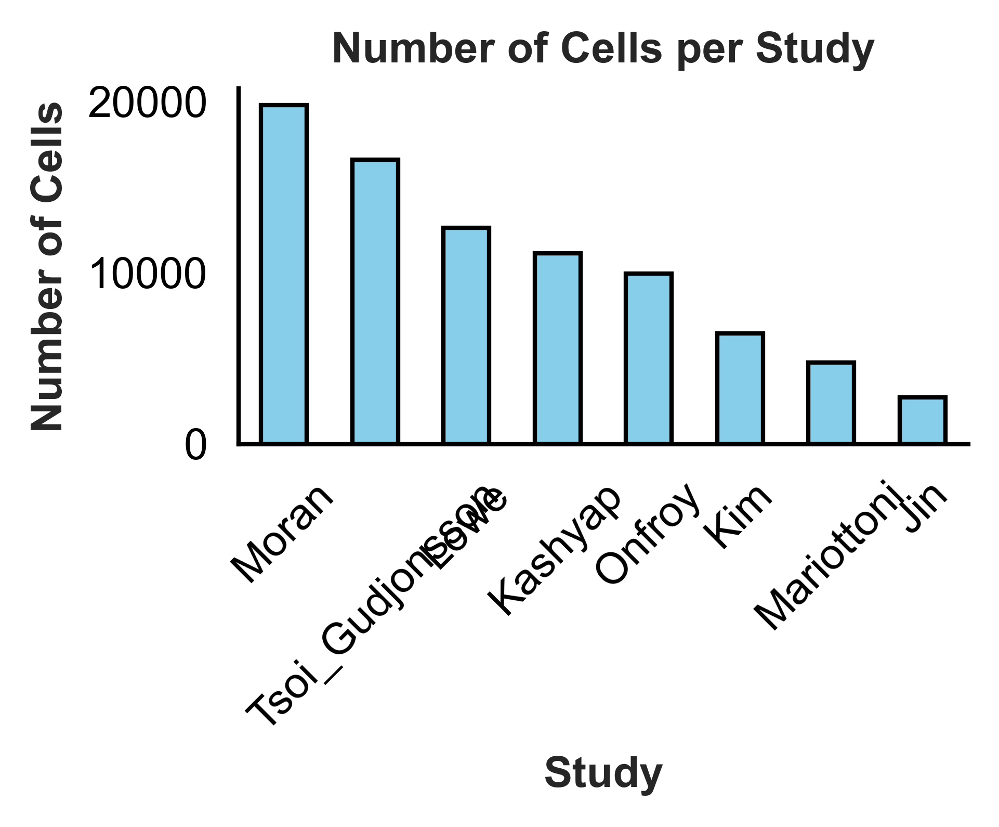

In [56]:
cell_counts = integrated_adata.obs["Study"].value_counts()

fig, ax = plt.subplots(figsize=(3, 1.5))
cell_counts.plot(kind="bar", color="skyblue", edgecolor="black", ax=ax)
ax.set_title("Number of Cells per Study", fontweight="bold")
ax.set_xlabel("Study", fontweight="bold")
ax.set_ylabel("Number of Cells", fontweight="bold")
ax.tick_params(axis="x", rotation=45)
ax.grid(False)

fig.tight_layout()
fig.savefig(FIG_DIR / "figure-1.pdf", bbox_inches="tight")
plt.show()


In [57]:
counts_df = cell_counts.rename("n_cells").to_frame()
counts_df["fraction"] = counts_df["n_cells"] / counts_df["n_cells"].sum()


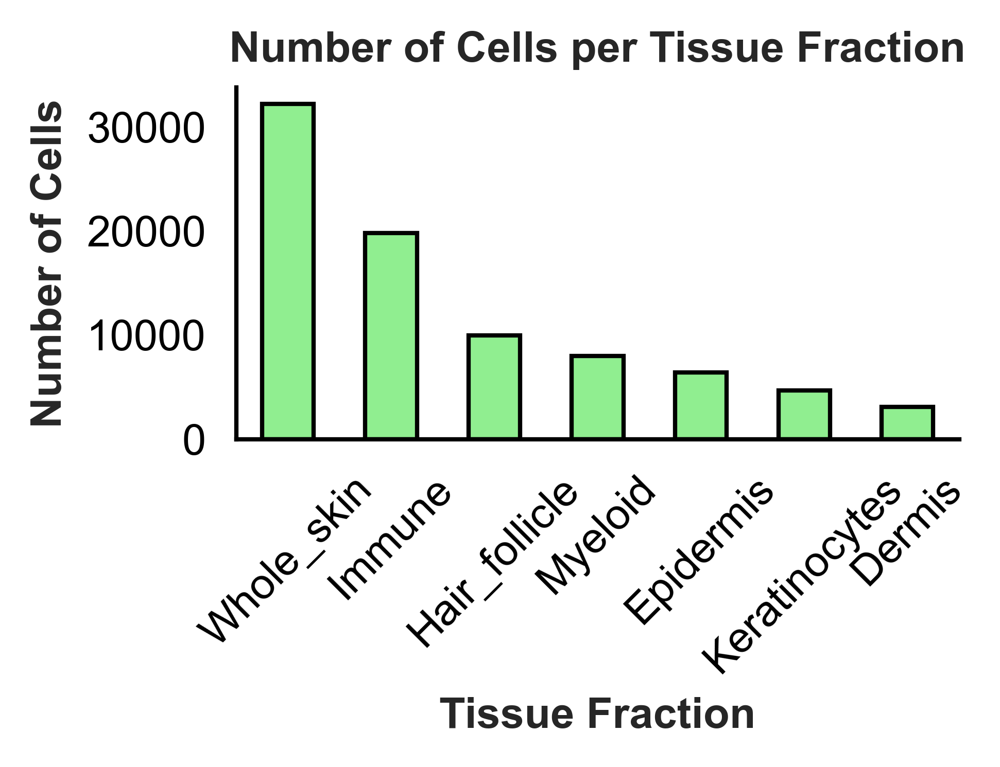

In [58]:
tissue_counts = integrated_adata.obs["Tissue_Fraction"].value_counts()

fig, ax = plt.subplots(figsize=(3, 1.5))
tissue_counts.plot(kind="bar", color="lightgreen", edgecolor="black", ax=ax)
ax.set_title("Number of Cells per Tissue Fraction", fontweight="bold")
ax.set_xlabel("Tissue Fraction", fontweight="bold")
ax.set_ylabel("Number of Cells", fontweight="bold")
ax.tick_params(axis="x", rotation=45)
ax.grid(False)


fig.savefig(FIG_DIR / "figure-2.pdf", bbox_inches="tight")
plt.show()


In [59]:
tissue_df = tissue_counts.rename("n_cells").to_frame()
tissue_df["fraction"] = tissue_df["n_cells"] / tissue_df["n_cells"].sum()


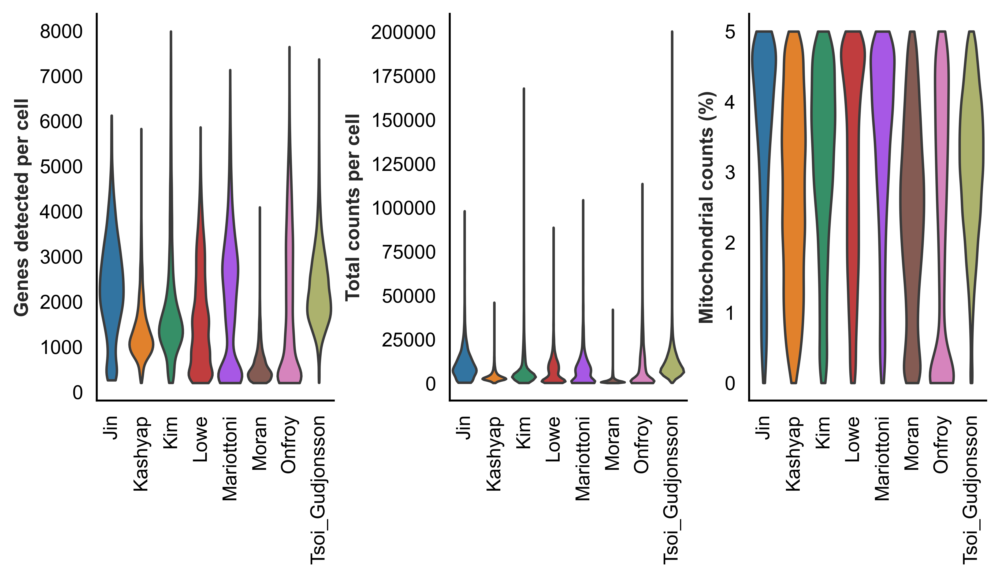

In [60]:
features = ["n_genes_by_counts", "total_counts", "pct_counts_mt"]

ylabels = {
    "n_genes_by_counts": "Genes detected per cell",
    "total_counts": "Total counts per cell",
    "pct_counts_mt": "Mitochondrial counts (%)",
}

fig, axs = plt.subplots(1, 3, figsize=(7, 4), constrained_layout=True)

for ax, f in zip(axs, features):
    sc.pl.violin(
        integrated_adata,
        f,
        groupby="Study",
        rotation=90,
        show=False,
        ax=ax,
        stripplot=False,
    )
    ax.set_title(ax.get_title(), fontweight="bold")
    ax.set_xlabel(ax.get_xlabel(), fontweight="bold")
    ax.set_ylabel(ylabels[f], fontweight="bold")
    ax.grid(False)


fig.savefig(FIG_DIR / "figure-3.pdf", bbox_inches="tight", dpi=300)
plt.show()


In [61]:
def _iqr(s: pd.Series) -> float:
    return float(s.quantile(0.75) - s.quantile(0.25))

qc = integrated_adata.obs[["Study"] + features].copy()
grp = qc.groupby("Study", observed=False)

qc_summary = pd.DataFrame({
    "n_cells": grp.size(),
    "n_genes_median": grp["n_genes_by_counts"].median(),
    "n_genes_IQR": grp["n_genes_by_counts"].apply(_iqr),
    "total_counts_median": grp["total_counts"].median(),
    "total_counts_IQR": grp["total_counts"].apply(_iqr),
    "pct_mt_median": grp["pct_counts_mt"].median(),
    "pct_mt_IQR": grp["pct_counts_mt"].apply(_iqr),
}).sort_index()


In [62]:
import matplotlib as mpl

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "figure.titlesize": 10,
    "figure.labelsize": 10,
})


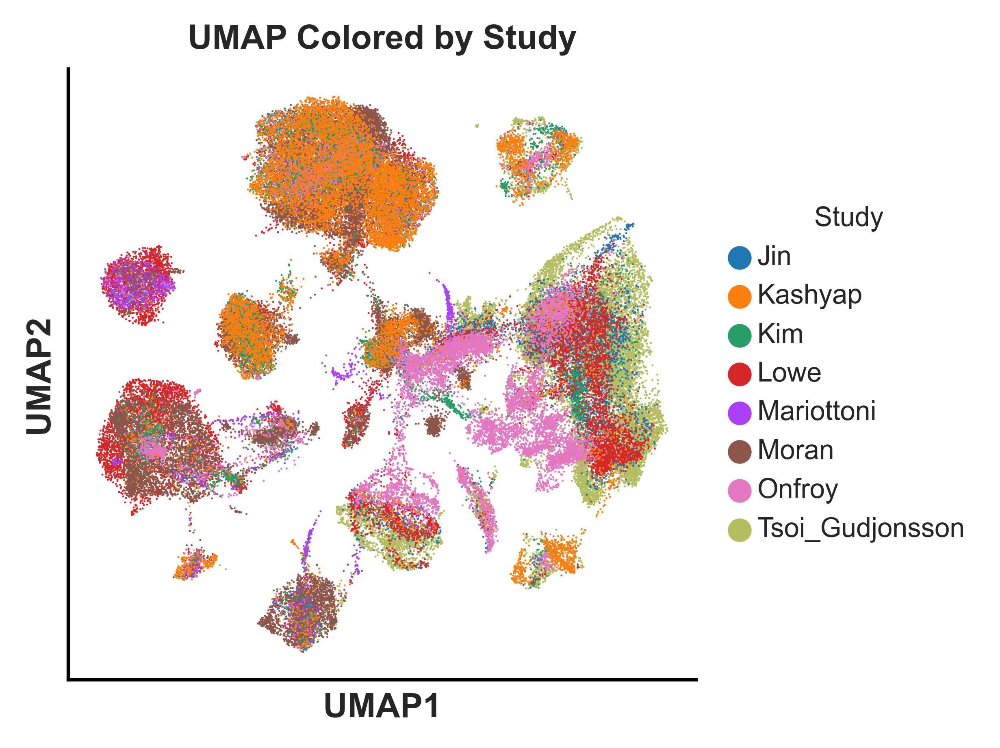

In [63]:
fig, ax = plt.subplots(figsize=(3.3, 3.3))
sc.settings.set_figure_params(vector_friendly=True, dpi_save=300)
sc.pl.umap(
    integrated_adata,
    color="Study",
    title="UMAP Colored by Study",
    ax=ax,
    show=False,
    legend_loc="right margin",
    legend_fontsize=8,
)
ax.set_title(ax.get_title(), fontsize=10, fontweight="bold")
ax.set_xlabel(ax.get_xlabel(), fontsize=10, fontweight="bold")
ax.set_ylabel(ax.get_ylabel(), fontsize=10, fontweight="bold")
ax.grid(False)

leg = ax.get_legend()
if leg:
    handles, labels = ax.get_legend_handles_labels()
    leg.remove()
    ax.legend(
        handles,
        labels,
        title="Study",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=8,
        title_fontsize=8,
    )

fig.savefig(FIG_DIR / "figure-4a.pdf", bbox_inches="tight")
plt.show()


In [64]:
ct = pd.crosstab(integrated_adata.obs["leiden"], integrated_adata.obs["Study"])

K = ct.shape[1]
logK = np.log(K) if K > 1 else 1.0

def norm_entropy(row: pd.Series) -> float:
    p = row.values.astype(float)
    s = p.sum()
    if s <= 0:
        return 0.0
    p = p / s
    p = p[p > 0]
    H = float(-(p * np.log(p)).sum())
    return float(H / logK) if logK > 0 else 0.0

cluster_entropy = ct.apply(norm_entropy, axis=1)
cluster_sizes = ct.sum(axis=1)
weighted_mean_entropy = float((cluster_entropy * cluster_sizes).sum() / cluster_sizes.sum())

least_mixed = (
    pd.DataFrame({"cluster": cluster_entropy.index, "norm_entropy": cluster_entropy.values, "n_cells": cluster_sizes.values})
    .sort_values(["norm_entropy", "n_cells"], ascending=[True, False])
    .head(8)
)


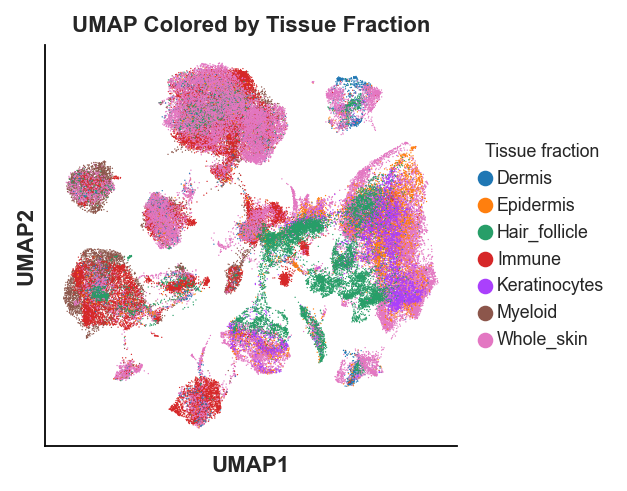

In [65]:
fig, ax = plt.subplots(figsize=(3.3, 3.3))
sc.settings.set_figure_params(vector_friendly=True, dpi_save=300)
sc.pl.umap(
    integrated_adata,
    color="Tissue_Fraction",
    title="UMAP Colored by Tissue Fraction",
    ax=ax,
    show=False,
    legend_loc="right margin",
    legend_fontsize=8,
)
ax.set_title(ax.get_title(), fontsize=10, fontweight="bold")
ax.set_xlabel(ax.get_xlabel(), fontsize=10, fontweight="bold")
ax.set_ylabel(ax.get_ylabel(), fontsize=10, fontweight="bold")
ax.grid(False)

leg = ax.get_legend()
if leg:
    handles, labels = ax.get_legend_handles_labels()
    leg.remove()
    ax.legend(
        handles,
        labels,
        title="Tissue fraction",
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=8,
        title_fontsize=8,
    )

fig.savefig(FIG_DIR / "figure-4b.pdf", bbox_inches="tight")
plt.show()


In [66]:
ct_tf = pd.crosstab(integrated_adata.obs["leiden"], integrated_adata.obs["Tissue_Fraction"])
K_tf = ct_tf.shape[1]
logK_tf = np.log(K_tf) if K_tf > 1 else 1.0

def norm_entropy_tf(row: pd.Series) -> float:
    p = row.values.astype(float)
    s = p.sum()
    if s <= 0:
        return 0.0
    p = p / s
    p = p[p > 0]
    H = float(-(p * np.log(p)).sum())
    return float(H / logK_tf) if logK_tf > 0 else 0.0

cluster_entropy_tf = ct_tf.apply(norm_entropy_tf, axis=1)
cluster_sizes_tf = ct_tf.sum(axis=1)
weighted_mean_entropy_tf = float((cluster_entropy_tf * cluster_sizes_tf).sum() / cluster_sizes_tf.sum())

least_mixed_tf = (
    pd.DataFrame({"cluster": cluster_entropy_tf.index, "norm_entropy": cluster_entropy_tf.values, "n_cells": cluster_sizes_tf.values})
    .sort_values(["norm_entropy", "n_cells"], ascending=[True, False])
    .head(8)
)


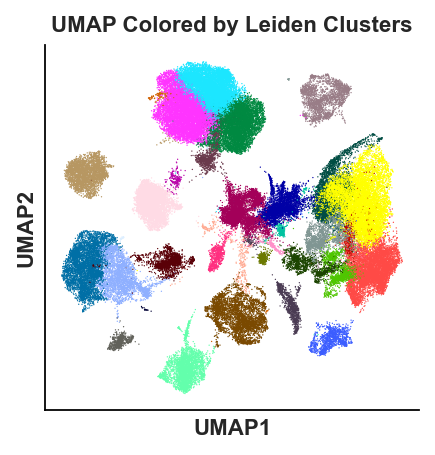

In [67]:
fig, ax = plt.subplots(figsize=(3,3))
sc.pl.umap(
    integrated_adata,
    color="leiden",
    title="UMAP Colored by Leiden Clusters",
    ax=ax,
    show=False,
    legend_loc="none",
)
ax.set_title(ax.get_title(),fontsize=10, fontweight="bold")
ax.set_xlabel(ax.get_xlabel(),fontsize=10, fontweight="bold")
ax.set_ylabel(ax.get_ylabel(),fontsize=10, fontweight="bold")
ax.grid(False)


fig.savefig(FIG_DIR / "figure-4c.pdf", bbox_inches="tight")
plt.show()


In [68]:
cluster_counts = integrated_adata.obs["leiden"].value_counts().sort_index()
cluster_df = cluster_counts.rename("n_cells").to_frame()
cluster_df["fraction"] = cluster_df["n_cells"] / cluster_df["n_cells"].sum()


In [69]:
sc.tl.rank_genes_groups(
    integrated_adata,
    groupby="leiden",
    method="wilcoxon",
)


In [70]:
cluster_to_celltype = {
    "0":  "Keratinocytes (S100A8/A9+)",
    "1":  "T Cells",
    "2":  "T Cells",
    "3":  "Keratinocytes (CXCL14+)",
    "4":  "Cytotoxic T/NK Cells",
    "5":  "Myeloid / Dendritic Cells",
    "6":  "Unresolved Cells",
    "7":  "B/Plasma Cells",
    "8":  "Cycling Cells",
    "9":  "Keratinocytes",
    "10": "B/Plasma Cells",
    "11": "Myeloid / Dendritic Cells",
    "12": "Keratinocytes",
    "13": "Myeloid / Dendritic Cells",
    "14": "Fibroblasts",
    "15": "Myeloid / Dendritic Cells",
    "16": "Keratinocytes",
    "17": "Stress-response Cells",
    "18": "Melanocytes",
    "19": "Unresolved Cells",
    "20": "Endothelial Cells",
    "21": "Melanocytes",
    "22": "Mast Cells",
    "23": "Myeloid / Dendritic Cells",
    "24": "Keratinocytes",
    "25": "Myeloid / Dendritic Cells",
    "26": "B/Plasma Cells",
    "27": "Cycling Cells",
    "28": "Keratinocytes (S100A8/A9+)",
    "29": "B/Plasma Cells",
    "30": "Cycling Cells",
    "31": "Myeloid / Dendritic Cells",
    "32": "Cycling Cells",
}

if "cell_type_major" in integrated_adata.obs:
    del integrated_adata.obs["cell_type_major"]
if "cell_type_major_colors" in integrated_adata.uns:
    del integrated_adata.uns["cell_type_major_colors"]

integrated_adata.obs["cell_type_major"] = integrated_adata.obs["leiden"].map(cluster_to_celltype)
integrated_adata.obs["cell_type_major"] = integrated_adata.obs["cell_type_major"].astype("category")


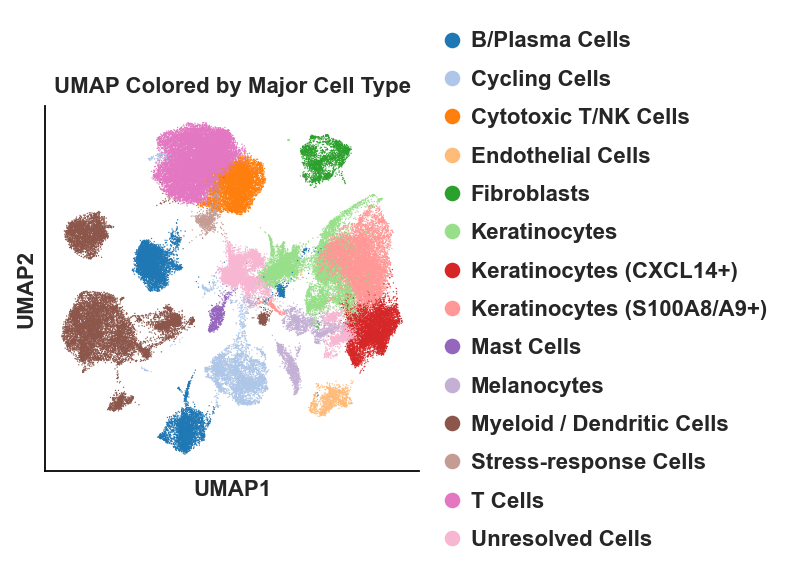

In [71]:
ct = integrated_adata.obs["cell_type_major"].astype("category")
cats = sorted(list(ct.cat.categories))
integrated_adata.obs["cell_type_major"] = ct.cat.reorder_categories(cats)

palette = sns.color_palette("tab20", len(cats)).as_hex()
integrated_adata.uns["cell_type_major_colors"] = palette

fig, ax = plt.subplots(figsize=(3,3))
sc.pl.umap(
    integrated_adata,
    color="cell_type_major",
    title="UMAP Colored by Major Cell Type",
    ax=ax,
    show=False,
)
ax.set_title(ax.get_title(),fontsize=10, fontweight="bold")
ax.set_xlabel(ax.get_xlabel(),fontsize=10, fontweight="bold")
ax.set_ylabel(ax.get_ylabel(),fontsize=10, fontweight="bold")
ax.grid(False)

leg = ax.get_legend()
if leg:
    plt.setp(leg.get_title(), fontsize=10,fontweight="bold")
    plt.setp(leg.get_texts(), fontsize=10, fontweight="bold")


fig.savefig(FIG_DIR / "figure-5.pdf", bbox_inches="tight")
plt.show()


In [72]:
ct_counts = integrated_adata.obs["cell_type_major"].value_counts()
ct_df = ct_counts.rename("n_cells").to_frame()
ct_df["fraction"] = ct_df["n_cells"] / ct_df["n_cells"].sum()


dom_map = (
    integrated_adata.obs
    .groupby(["leiden", "cell_type_major"], observed=False)
    .size()
    .reset_index(name="n")
    .sort_values(["leiden", "n"], ascending=[True, False])
    .groupby("leiden", observed=False)
    .head(1)
    .set_index("leiden")[["cell_type_major", "n"]]
)


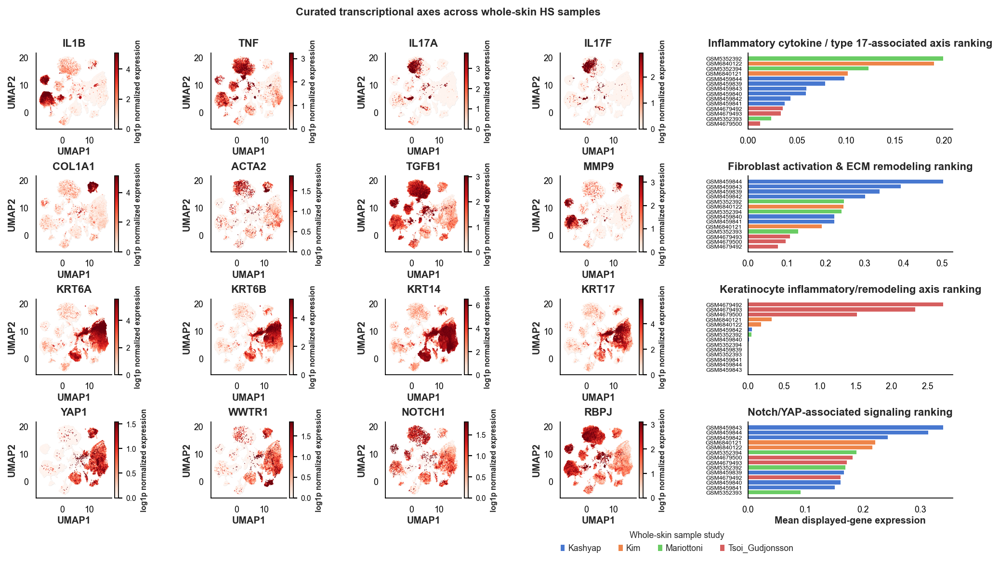

In [73]:
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.titlesize": 10,
})

from matplotlib.patches import Patch

whole_skin_mask_global = integrated_adata.obs["Tissue_Fraction"].astype(str) == "Whole_skin"
whole_sample_study = (
    integrated_adata.obs.loc[whole_skin_mask_global, ["GSM", "Study"]]
    .drop_duplicates("GSM")
    .set_index("GSM")["Study"]
    .astype(str)
)
whole_studies = sorted(whole_sample_study.dropna().unique().tolist())
study_palette = dict(zip(whole_studies, sns.color_palette("muted", n_colors=max(1, len(whole_studies)))))

def _target_gene_ws_coverage(gene):
    if "TARGET_GENE_AVAILABILITY" not in globals() or gene not in TARGET_GENE_AVAILABILITY.columns:
        return 0.0
    gmss = [g for g in whole_sample_study.index if g in TARGET_GENE_AVAILABILITY.index]
    if len(gmss) == 0:
        return 0.0
    return float(TARGET_GENE_AVAILABILITY.loc[gmss, gene].mean())

def get_first_n_present_genes(adata, ranked_genes, n=4):

    full = [g for g in ranked_genes if _target_gene_ws_coverage(g) >= 0.999]
    if len(full) >= n:
        return full[:n]

    broad = [g for g in ranked_genes if _target_gene_ws_coverage(g) >= 0.80]
    if len(broad) >= n:
        return broad[:n]

    var_names = adata.raw.var_names if adata.raw is not None else adata.var_names
    fallback = [g for g in ranked_genes if g in var_names]
    return list(dict.fromkeys(full + broad + fallback))[:n]

def _target_values_for_cells(adata, genes):
    genes = [g for g in genes if g in TARGET_EXPR.columns]
    if len(genes) == 0:
        return pd.DataFrame(index=adata.obs_names)
    if "_cell_uid" not in adata.obs:
        raise ValueError("_cell_uid missing; rerun Cell 4.")
    uid = adata.obs["_cell_uid"].astype(str).values
    out = TARGET_EXPR.reindex(uid)[genes].copy()
    out.index = adata.obs_names
    return out

def _plot_target_umap(adata, gene, ax):
    coords = np.asarray(adata.obsm["X_umap"])
    vals = _target_values_for_cells(adata, [gene])[gene].to_numpy(dtype=float)
    valid = np.isfinite(vals)


    ax.scatter(coords[:, 0], coords[:, 1], s=0.35, c="0.90", linewidths=0, rasterized=True)
    if valid.any():
        vv = vals[valid]
        vmax = np.nanpercentile(vv, 99.5)
        if not np.isfinite(vmax) or vmax <= 0:
            vmax = np.nanmax(vv) if np.isfinite(np.nanmax(vv)) else 1.0
        if not np.isfinite(vmax) or vmax <= 0:
            vmax = 1.0
        ord_idx = np.argsort(vv)
        im = ax.scatter(
            coords[valid, 0][ord_idx], coords[valid, 1][ord_idx],
            c=vv[ord_idx], cmap="Reds", vmin=0, vmax=vmax,
            s=0.45, linewidths=0, rasterized=True,
        )
        cb = ax.figure.colorbar(im, ax=ax, fraction=0.045, pad=0.02)
        cb.set_label("log1p normalized expression", fontsize=7)
        cb.ax.tick_params(labelsize=7)
    ax.set_title(gene, fontweight="bold", fontsize=10, pad=6)
    ax.set_xlabel("UMAP1", fontsize=9, fontweight="bold", labelpad=2)
    ax.set_ylabel("UMAP2", fontsize=9, fontweight="bold", labelpad=2)
    ax.tick_params(axis="both", labelsize=8)
    ax.grid(False)
    ax.set_box_aspect(1)

def plot_pathway_ranking(adata, genes, pathway_name, ax, show_xlabel=True):
    whole_skin_mask = adata.obs["Tissue_Fraction"].astype(str) == "Whole_skin"
    if not whole_skin_mask.any():
        ax.text(0.5, 0.5, "No Whole_skin samples", ha="center", va="center", fontsize=10)
        ax.set_title(f"{pathway_name} ranking", fontweight="bold", fontsize=10, pad=6)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        return None

    sub = adata[whole_skin_mask]
    expr_df = _target_values_for_cells(sub, genes)
    genes_present = [g for g in genes if g in expr_df.columns and expr_df[g].notna().any()]
    if len(genes_present) == 0:
        ax.text(0.5, 0.5, "No displayed genes available", ha="center", va="center", fontsize=10)
        ax.set_title(f"{pathway_name} ranking", fontweight="bold", fontsize=10, pad=6)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        return None

    expr_df = expr_df[genes_present]
    expr_df["GSM"] = sub.obs["GSM"].astype(str).values
    expr_df["axis_score"] = expr_df[genes_present].mean(axis=1, skipna=True)
    sample_scores = (
        expr_df.groupby("GSM", observed=False)["axis_score"]
        .mean()
        .sort_values(ascending=False)
    )

    scores_df = sample_scores.reset_index()
    scores_df.columns = ["GSM", "axis_score"]
    scores_df["Study"] = scores_df["GSM"].map(whole_sample_study).fillna("Unknown")
    bar_colors = [study_palette.get(s, (0.5, 0.5, 0.5)) for s in scores_df["Study"]]

    y_pos = np.arange(scores_df.shape[0])
    ax.barh(y_pos, scores_df["axis_score"].values, color=bar_colors, edgecolor="none", height=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(scores_df["GSM"].tolist(), fontsize=5.5)
    ax.invert_yaxis()
    ax.set_title(f"{pathway_name} ranking", fontweight="bold", fontsize=10, pad=6)
    ax.set_xlabel("Mean displayed-gene expression" if show_xlabel else "", fontsize=9, labelpad=2)
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=5.5, pad=2)
    ax.grid(False)
    return scores_df


inflammation_genes_ranked = [
    "IL1B", "TNF", "IL17A", "IL17F",
    "IL23A", "IL6", "CXCL1", "CXCL2", "CXCL8", "CCL20",
    "S100A8", "S100A9", "NLRP3",
    "CXCL10", "CXCL11", "IL36A", "IL36G", "PTGS2", "IFNG",
]
fibrosis_genes_ranked = [
    "COL1A1", "ACTA2", "TGFB1", "MMP9",
    "COL1A2", "COL3A1", "COL5A1", "COL5A2", "COL6A1", "COL6A3", "COL14A1",
    "FN1", "LUM", "DCN", "TAGLN", "CTGF", "THBS1", "SERPINE1", "LOX",
    "MMP2", "TIMP1", "PDGFRB", "PDGFRA",
]
antimicrobial_epith_genes_ranked = [
    "KRT6A", "KRT6B", "KRT14", "KRT17", "KRT5",
    "SOX9", "KLF5", "GATA3", "S100A7", "S100A8", "S100A9",
    "KRT1", "KRT10", "SPRR1B", "SPRR2D", "LOR",
    "CXCL13", "ICAM1", "IL33",
]
transcription_genes_ranked = [
    "YAP1", "WWTR1", "NOTCH1", "RBPJ",
    "NCSTN", "PSENEN", "PSEN1", "NOTCH2", "NOTCH3", "JAG1", "JAG2",
    "DLL1", "HES1", "MAML1", "TEAD1", "TEAD4", "CTGF", "CYR61", "KLF4",
]

pathways = [
    ("Inflammatory cytokine / type 17-associated axis", inflammation_genes_ranked),
    ("Fibroblast activation & ECM remodeling", fibrosis_genes_ranked),
    ("Keratinocyte inflammatory/remodeling axis", antimicrobial_epith_genes_ranked),
    ("Notch/YAP-associated signaling", transcription_genes_ranked),
]

n_rows = len(pathways)
fig, axs = plt.subplots(
    n_rows, 6, figsize=(13.5, 7.4),
    gridspec_kw={"width_ratios": [1, 1, 1, 1, 0.25, 1.45]}
)
if n_rows == 1:
    axs = axs.reshape(1, -1)

fig.subplots_adjust(left=0.05, right=0.985, bottom=0.12, top=0.90, wspace=0.25, hspace=0.62)

figure6_genes_used = {}
figure6_gene_coverage = {}

for row_idx, (path_name, ranked_genes) in enumerate(pathways):
    genes_to_use = get_first_n_present_genes(integrated_adata, ranked_genes, n=4)
    figure6_genes_used[path_name] = genes_to_use
    figure6_gene_coverage[path_name] = {g: _target_gene_ws_coverage(g) for g in genes_to_use}

    for col_idx in range(4):
        ax = axs[row_idx, col_idx]
        if col_idx < len(genes_to_use):
            _plot_target_umap(integrated_adata, genes_to_use[col_idx], ax)
        else:
            ax.axis("off")

    axs[row_idx, 4].axis("off")
    ax_rank = axs[row_idx, 5]
    _ = plot_pathway_ranking(
        integrated_adata, genes_to_use, path_name, ax_rank,
        show_xlabel=(row_idx == n_rows - 1),
    )

if study_palette:
    study_handles = [Patch(facecolor=study_palette[s], edgecolor="none", label=s) for s in whole_studies]
    fig.legend(
        handles=study_handles, title="Whole-skin sample study",
        loc="lower center", bbox_to_anchor=(0.72, 0.01),
        ncol=min(4, len(study_handles)), frameon=False,
        fontsize=8, title_fontsize=8,
    )

fig.suptitle("Curated transcriptional axes across whole-skin HS samples", fontsize=10, fontweight="bold")
fig.savefig(FIG_DIR / "figure-6.pdf", bbox_inches="tight")
plt.show()


In [74]:
def compute_wholeskin_sample_scores(adata, genes):
    ws_mask = adata.obs["Tissue_Fraction"].astype(str) == "Whole_skin"
    if not ws_mask.any():
        return None
    sub = adata[ws_mask]
    df = _target_values_for_cells(sub, genes)
    genes_present = [g for g in genes if g in df.columns and df[g].notna().any()]
    if len(genes_present) == 0:
        return None
    df = df[genes_present]
    df["GSM"] = sub.obs["GSM"].astype(str).values
    df["score"] = df[genes_present].mean(axis=1, skipna=True)
    return df.groupby("GSM", observed=False)["score"].mean().sort_values(ascending=False)

def summarize_wholeskin_gene(adata, gene):
    ws_mask = adata.obs["Tissue_Fraction"].astype(str) == "Whole_skin"
    sub = adata[ws_mask]
    if gene not in TARGET_EXPR.columns:
        return None
    vals = _target_values_for_cells(sub, [gene])[gene].to_numpy(dtype=float)
    tmp = pd.DataFrame({
        "GSM": sub.obs["GSM"].astype(str).values,
        "expr": vals,
    }).dropna(subset=["expr"])
    if tmp.empty:
        return None
    return tmp.groupby("GSM", observed=False).agg(
        mean_expression=("expr", "mean"),
        detection_fraction=("expr", lambda x: float((x > 0).mean())),
    )


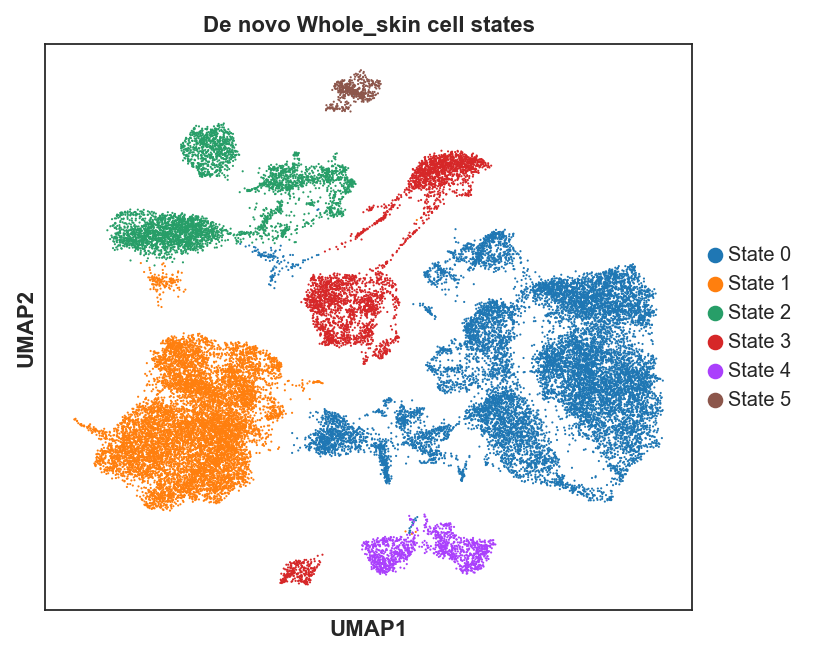

In [75]:
sns.set_style("white")


ws_mask = integrated_adata.obs["Tissue_Fraction"].astype(str) == "Whole_skin"
ws_adata = integrated_adata[ws_mask].copy()

try:
    sc.pp.neighbors(ws_adata, use_rep="X_pca_harmony", n_neighbors=10, random_state=SEED)
except TypeError:
    sc.pp.neighbors(ws_adata, use_rep="X_pca_harmony", n_neighbors=10)

try:
    sc.tl.umap(ws_adata, random_state=SEED)
except TypeError:
    sc.tl.umap(ws_adata)

cluster_key = "WS_Endotype"
try:
    sc.tl.leiden(ws_adata, resolution=0.02, key_added=cluster_key, random_state=SEED)
except TypeError:
    sc.tl.leiden(ws_adata, resolution=0.02, key_added=cluster_key)

ws_adata.obs[cluster_key] = ws_adata.obs[cluster_key].astype(str)
state_order = sorted(
    ws_adata.obs[cluster_key].unique().tolist(),
    key=lambda x: (0, int(x)) if str(x).isdigit() else (1, str(x)),
)
ws_adata.obs["WS_State_Label"] = pd.Categorical(
    "State " + ws_adata.obs[cluster_key].astype(str),
    categories=["State " + str(x) for x in state_order],
    ordered=True,
)


from sklearn.metrics import adjusted_rand_score

reference_labels = ws_adata.obs[cluster_key].astype(str).values.copy()
sensitivity_resolutions = [0.01, 0.015, 0.02, 0.025, 0.03, 0.04]
sensitivity_rows = []

for res in sensitivity_resolutions:
    if np.isclose(res, 0.02):
        labels = reference_labels
    else:
        tmp_key = f"_WS_state_res_{str(res).replace('.', 'p')}"
        try:
            sc.tl.leiden(ws_adata, resolution=res, key_added=tmp_key, random_state=SEED)
        except TypeError:
            sc.tl.leiden(ws_adata, resolution=res, key_added=tmp_key)
        labels = ws_adata.obs[tmp_key].astype(str).values.copy()
        del ws_adata.obs[tmp_key]

    sensitivity_rows.append({
        "resolution": float(res),
        "n_states": int(pd.Series(labels).nunique()),
        "ARI_vs_resolution_0.02": float(adjusted_rand_score(reference_labels, labels)),
    })

state_resolution_sensitivity = pd.DataFrame(sensitivity_rows)


myeloid_pyogenic_genes_ranked = [
    "IL1B", "TNF", "IL6",
    "NLRP3", "PYCARD", "CASP1",
    "CXCL1", "CXCL2", "CXCL3", "CXCL5", "CXCL8",
    "CCL2", "CCL3", "CCL4", "CCL20",
    "S100A8", "S100A9", "S100A12",
    "CSF3R", "CSF1R",
    "TLR2", "TLR4", "PTGS2",
]

th17_jak_genes_ranked = [
    "IL23A", "IL12B", "IL17A", "IL17F",
    "RORC", "CCR6", "CD3D", "CD3E", "CD4", "ICOS",
    "STAT3", "STAT1", "JAK1", "JAK3", "TYK2",
    "IFNG", "CXCL9", "CXCL10", "CXCL11",
    "CXCL13",
]

tgfb_pdgf_fibro_genes_ranked = [
    "COL1A1", "COL1A2", "COL3A1", "FN1",
    "ACTA2", "TAGLN",
    "TGFB1", "TGFBR1", "TGFBR2", "SMAD3",
    "PDGFRA", "PDGFRB",
    "CTGF", "THBS1", "SERPINE1", "LOX",
    "MMP2", "MMP9", "TIMP1",
    "COL5A1", "COL5A2", "COL6A1", "COL6A3", "LUM", "DCN",
]

epithelial_notch_yap_genes_ranked = [
    "KRT14", "KRT17", "KRT6A", "KRT6B", "KRT5",
    "SOX9", "KLF5", "GATA3",
    "EGFR", "AREG", "EREG",
    "NCSTN", "PSENEN",
    "NOTCH1", "NOTCH2", "NOTCH3",
    "JAG1", "JAG2", "HES1", "RBPJ",
    "YAP1", "WWTR1", "TEAD1", "TEAD4", "CTGF",
]

gene_sets = {
    "Myeloid TNF/IL-1/NLRP3-associated": myeloid_pyogenic_genes_ranked,
    "Type 17/T-cell JAK-STAT-associated": th17_jak_genes_ranked,
    "TGFβ/PDGF fibro-ECM": tgfb_pdgf_fibro_genes_ranked,
    "Epithelial remodeling/Notch-YAP-EGFR-associated": epithelial_notch_yap_genes_ranked,
}


if ws_adata.raw is not None:
    var_ref = ws_adata.raw.var_names
    use_raw = True
else:
    var_ref = ws_adata.var_names
    use_raw = False

seen = set()
ordered_genes = []
ordered_paths = []
for pname, genes in gene_sets.items():
    for g in genes:
        if g in var_ref and g not in seen:
            seen.add(g)
            ordered_genes.append(g)
            ordered_paths.append(pname)

if len(ordered_genes) == 0:
    raise ValueError("None of the curated program genes are present in var/raw.var.")

if use_raw:
    raw_ws = ws_adata.raw.to_adata()
    expr_mat = raw_ws[:, ordered_genes].X
else:
    expr_mat = ws_adata[:, ordered_genes].X

if issparse(expr_mat):
    expr_mat = expr_mat.toarray()

expr_df = pd.DataFrame(expr_mat, index=ws_adata.obs_names, columns=ordered_genes)

cluster_labels = ws_adata.obs[cluster_key]
cluster_means = expr_df.groupby(cluster_labels, observed=False).mean().T
cluster_means = cluster_means.reindex(columns=state_order)

cluster_means_z = cluster_means.copy()
cluster_means_z = cluster_means_z.sub(cluster_means_z.mean(axis=1), axis=0)
cluster_means_z = cluster_means_z.div(cluster_means_z.std(axis=1).replace(0, np.nan), axis=0)
cluster_means_z = cluster_means_z.fillna(0.0).loc[ordered_genes]

path_series = pd.Series(ordered_paths, index=ordered_genes)
path_names_order = list(dict.fromkeys(ordered_paths))


def _whole_skin_broad_ct(x):
    s = str(x)
    if "Keratinocyte" in s:
        return "Keratinocyte"
    if s in ["T Cells", "Cytotoxic T/NK Cells"]:
        return "T/NK"
    if s == "Myeloid / Dendritic Cells":
        return "Myeloid/DC"
    if s == "B/Plasma Cells":
        return "B/Plasma"
    if s == "Fibroblasts":
        return "Fibroblast"
    return "Other"

ws_adata.obs["WS_Broad_Celltype"] = ws_adata.obs["cell_type_major"].map(_whole_skin_broad_ct)

state_sample_counts = pd.crosstab(ws_adata.obs["GSM"].astype(str), ws_adata.obs[cluster_key].astype(str))
state_sample_counts = state_sample_counts.reindex(columns=state_order, fill_value=0)
state_sample_fractions = state_sample_counts.div(state_sample_counts.sum(axis=1), axis=0)

state_study_counts = pd.crosstab(ws_adata.obs[cluster_key].astype(str), ws_adata.obs["Study"].astype(str))
state_study_counts = state_study_counts.reindex(index=state_order, fill_value=0)
state_study_fraction = state_study_counts.div(state_study_counts.sum(axis=1), axis=0)

state_broad_counts = pd.crosstab(ws_adata.obs[cluster_key].astype(str), ws_adata.obs["WS_Broad_Celltype"].astype(str))
state_broad_counts = state_broad_counts.reindex(index=state_order, fill_value=0)
state_broad_fraction = state_broad_counts.div(state_broad_counts.sum(axis=1), axis=0)

sc.tl.rank_genes_groups(
    ws_adata,
    groupby=cluster_key,
    method="wilcoxon",
    use_raw=True if ws_adata.raw is not None else False,
)
state_marker_rows = []
for state in state_order:
    mdf = sc.get.rank_genes_groups_df(ws_adata, group=str(state)).head(10)
    for rank, (_, row) in enumerate(mdf.iterrows(), start=1):
        state_marker_rows.append({
            "state": str(state),
            "rank": rank,
            "gene": str(row["names"]),
            "score": float(row["scores"]) if "scores" in row and pd.notna(row["scores"]) else np.nan,
            "logfoldchanges": float(row["logfoldchanges"]) if "logfoldchanges" in row and pd.notna(row["logfoldchanges"]) else np.nan,
            "pvals_adj": float(row["pvals_adj"]) if "pvals_adj" in row and pd.notna(row["pvals_adj"]) else np.nan,
        })
state_top_markers = pd.DataFrame(state_marker_rows)


fig1, ax1 = plt.subplots(1, 1, figsize=(5.2, 4.2))
sc.pl.umap(
    ws_adata,
    color="WS_State_Label",
    ax=ax1,
    show=False,
    title="De novo Whole_skin cell states",
)
ax1.set_title(ax1.get_title(), fontweight="bold")
ax1.set_xlabel(ax1.get_xlabel(), fontweight="bold")
ax1.set_ylabel(ax1.get_ylabel(), fontweight="bold")
ax1.grid(False)
fig1.tight_layout()
plt.show()

ws_path = RESULTS_DIR / "wholeskin_cellstates.h5ad"
ws_adata.write_h5ad(ws_path, compression="gzip")


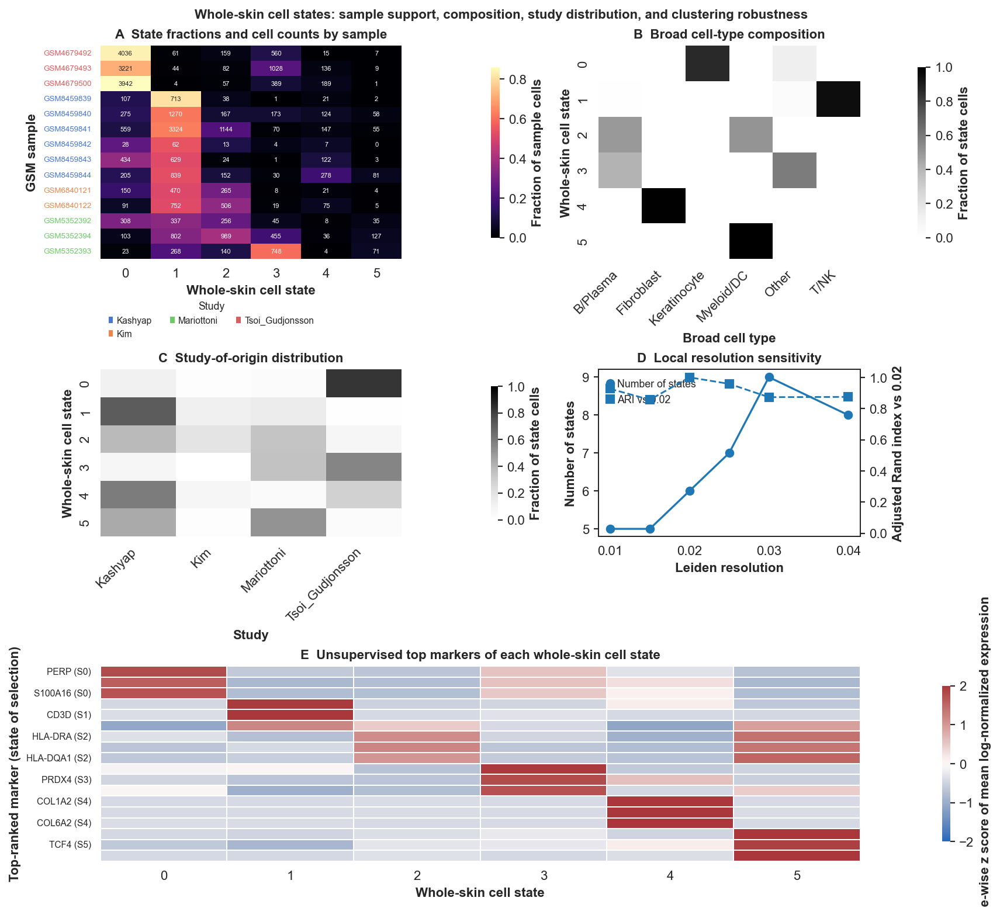

In [76]:
from matplotlib.patches import Patch

comp_counts = state_sample_counts.copy()
comp = state_sample_fractions.copy()

dominant = comp.idxmax(axis=1)
sample_study = (
    ws_adata.obs[["GSM", "Study"]]
    .drop_duplicates("GSM")
    .set_index("GSM")["Study"]
    .astype(str)
)
sample_order = (
    pd.DataFrame({
        "dominant_state": pd.Categorical(dominant, categories=state_order, ordered=True),
        "Study": sample_study.reindex(comp.index).astype(str),
    })
    .sort_values(["dominant_state", "Study"])
    .index
)

comp_plot = comp.loc[sample_order]
count_plot = comp_counts.loc[sample_order]
study_order_ws = sorted(sample_study.dropna().unique().tolist())
study_palette_ws = dict(zip(study_order_ws, sns.color_palette("muted", n_colors=max(1, len(study_order_ws)))))


marker_genes_plot = []
marker_gene_source_state = {}
for state in state_order:
    genes_state = (
        state_top_markers.loc[state_top_markers["state"].astype(str) == str(state)]
        .sort_values("rank")["gene"]
        .astype(str)
        .head(3)
        .tolist()
    )
    for g in genes_state:
        if g in var_ref and g not in marker_genes_plot:
            marker_genes_plot.append(g)
            marker_gene_source_state[g] = str(state)

if ws_adata.raw is not None:
    marker_X = ws_adata.raw[:, marker_genes_plot].X
else:
    marker_X = ws_adata[:, marker_genes_plot].X
if issparse(marker_X):
    marker_X = marker_X.toarray()
marker_expr = pd.DataFrame(np.asarray(marker_X), index=ws_adata.obs_names, columns=marker_genes_plot)
marker_means = marker_expr.groupby(ws_adata.obs[cluster_key].astype(str).values, observed=False).mean().T
marker_means = marker_means.reindex(columns=state_order)
marker_means_z = marker_means.sub(marker_means.mean(axis=1), axis=0)
marker_means_z = marker_means_z.div(marker_means.std(axis=1).replace(0, np.nan), axis=0).fillna(0.0)
marker_plot_labels = [f"{g} (S{marker_gene_source_state[g]})" for g in marker_genes_plot]
marker_means_z_plot = marker_means_z.copy()
marker_means_z_plot.index = marker_plot_labels

fig3 = plt.figure(figsize=(10.6, 9.6), constrained_layout=True)
gs3 = fig3.add_gridspec(3, 2, width_ratios=[1.15, 1.0], height_ratios=[1.15, 0.9, 1.05])

ax3a = fig3.add_subplot(gs3[0, 0])
ax3b = fig3.add_subplot(gs3[0, 1])
ax3c = fig3.add_subplot(gs3[1, 0])
ax3d = fig3.add_subplot(gs3[1, 1])
ax3e = fig3.add_subplot(gs3[2, :])

sns.heatmap(
    comp_plot,
    cmap="magma",
    vmin=0,
    vmax=max(0.70, float(comp_plot.to_numpy().max())),
    annot=count_plot,
    fmt="d",
    annot_kws={"fontsize": 5},
    ax=ax3a,
    cbar_kws={"label": "Fraction of sample cells", "shrink": 0.8},
)
ax3a.set_title("A  State fractions and cell counts by sample", fontweight="bold")
ax3a.set_xlabel("Whole-skin cell state", fontweight="bold")
ax3a.set_ylabel("GSM sample", fontweight="bold")
ax3a.tick_params(axis="y", labelsize=6)
for tick in ax3a.get_yticklabels():
    gsm = tick.get_text()
    tick.set_color(study_palette_ws.get(sample_study.get(gsm, ""), "black"))

if study_palette_ws:
    handles = [Patch(facecolor=study_palette_ws[s], edgecolor="none", label=s) for s in study_order_ws]
    ax3a.legend(
        handles=handles,
        title="Study",
        frameon=False,
        fontsize=7,
        title_fontsize=8,
        loc="upper left",
        bbox_to_anchor=(0.0, -0.16),
        ncol=min(3, len(handles)),
    )

sns.heatmap(
    state_broad_fraction,
    cmap="Greys",
    vmin=0,
    vmax=1,
    ax=ax3b,
    cbar_kws={"label": "Fraction of state cells", "shrink": 0.8},
)
ax3b.set_title("B  Broad cell-type composition", fontweight="bold")
ax3b.set_xlabel("Broad cell type", fontweight="bold")
ax3b.set_ylabel("Whole-skin cell state", fontweight="bold")
plt.setp(ax3b.get_xticklabels(), rotation=45, ha="right")

sns.heatmap(
    state_study_fraction,
    cmap="Greys",
    vmin=0,
    vmax=1,
    ax=ax3c,
    cbar_kws={"label": "Fraction of state cells", "shrink": 0.8},
)
ax3c.set_title("C  Study-of-origin distribution", fontweight="bold")
ax3c.set_xlabel("Study", fontweight="bold")
ax3c.set_ylabel("Whole-skin cell state", fontweight="bold")
plt.setp(ax3c.get_xticklabels(), rotation=45, ha="right")

ax3d.plot(
    state_resolution_sensitivity["resolution"],
    state_resolution_sensitivity["n_states"],
    marker="o",
    linewidth=1.5,
    label="Number of states",
)
ax3d.set_xlabel("Leiden resolution", fontweight="bold")
ax3d.set_ylabel("Number of states", fontweight="bold")
ax3d.set_title("D  Local resolution sensitivity", fontweight="bold")
ax3d.grid(False)

ax3d_2 = ax3d.twinx()
ax3d_2.plot(
    state_resolution_sensitivity["resolution"],
    state_resolution_sensitivity["ARI_vs_resolution_0.02"],
    marker="s",
    linestyle="--",
    linewidth=1.3,
    label="ARI vs 0.02",
)
ax3d_2.set_ylabel("Adjusted Rand index vs 0.02", fontweight="bold")
ax3d_2.set_ylim(-0.02, 1.05)
lines1, labels1 = ax3d.get_legend_handles_labels()
lines2, labels2 = ax3d_2.get_legend_handles_labels()
ax3d.legend(lines1 + lines2, labels1 + labels2, frameon=False, fontsize=8, loc="best")

sns.heatmap(
    marker_means_z_plot,
    cmap="vlag",
    center=0,
    vmin=-2,
    vmax=2,
    linewidths=0.2,
    linecolor="white",
    ax=ax3e,
    cbar_kws={"label": "Gene-wise z score of mean log-normalized expression", "shrink": 0.8},
)
ax3e.set_title("E  Unsupervised top markers of each whole-skin cell state", fontweight="bold")
ax3e.set_xlabel("Whole-skin cell state", fontweight="bold")
ax3e.set_ylabel("Top-ranked marker (state of selection)", fontweight="bold")
ax3e.tick_params(axis="y", labelsize=7)

fig3.suptitle(
    "Whole-skin cell states: sample support, composition, study distribution, and clustering robustness",
    fontweight="bold",
)
fig3.savefig(FIG_DIR / "figure-7.pdf", bbox_inches="tight")
plt.show()


In [77]:
dominant_state = comp_plot.idxmax(axis=1)
dominant_frac = comp_plot.max(axis=1)

summary_rows = []
for gsm in comp_plot.index:
    r = comp_plot.loc[gsm].sort_values(ascending=False)
    top = r.head(2)
    summary_rows.append({
        "GSM": gsm,
        "Study": sample_study.get(gsm, "Unknown"),
        "Dominant_State": dominant_state.loc[gsm],
        "Dominant_Fraction": float(dominant_frac.loc[gsm]),
        "Top2": "; ".join([f"{idx}:{val:.3f}" for idx, val in top.items()]),
    })

summary_df = pd.DataFrame(summary_rows).set_index("GSM")


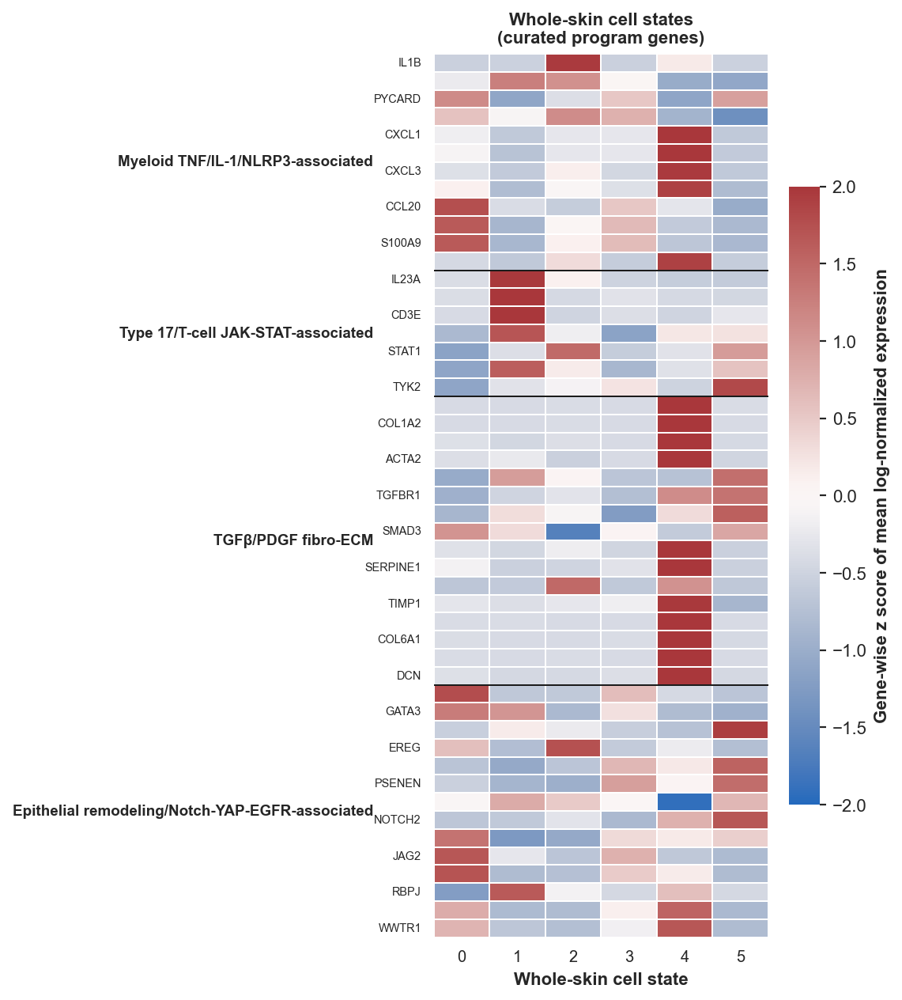

In [78]:
n_genes = cluster_means_z.shape[0]
fig2_height = max(7.2, 0.16 * n_genes)

fig2, ax2 = plt.subplots(1, 1, figsize=(5.8, fig2_height))

sns.heatmap(
    cluster_means_z,
    cmap="vlag",
    center=0,
    ax=ax2,
    cbar_kws={"label": "Gene-wise z score of mean log-normalized expression", "shrink": 0.7},
    vmin=-2,
    vmax=2,
    linewidths=0.15,
    linecolor="white",
)

ax2.set_title("Whole-skin cell states\n(curated program genes)", fontweight="bold")
ax2.set_xlabel("Whole-skin cell state", fontweight="bold")
ax2.set_ylabel("")
ax2.tick_params(axis="y", labelsize=6.5)
ax2.tick_params(axis="x", labelsize=9)

current_idx = 0
for pname in path_names_order:
    n_in_group = int((path_series == pname).sum())
    current_idx += n_in_group
    if current_idx < n_genes:
        ax2.hlines(current_idx, *ax2.get_xlim(), colors="black", linewidth=0.8)

current_idx = 0
for pname in path_names_order:
    n_in_group = int((path_series == pname).sum())
    if n_in_group == 0:
        continue
    mid = current_idx + n_in_group / 2.0
    ax2.text(
        -0.18,
        mid,
        pname,
        va="center",
        ha="right",
        fontsize=8.5,
        fontweight="bold",
        transform=ax2.get_yaxis_transform(),
        clip_on=False,
    )
    current_idx += n_in_group

fig2.subplots_adjust(left=0.39, right=0.96, top=0.95, bottom=0.06)
fig2.savefig(FIG_DIR / "figure-8.pdf", bbox_inches="tight")
plt.show()


In [79]:
states = list(cluster_means_z.columns)
pathway_mean_z = pd.DataFrame(index=states)
for pname in path_names_order:
    genes_in = path_series.index[path_series == pname].tolist()
    pathway_mean_z[pname] = cluster_means_z.loc[genes_in].mean(axis=0).values
pathway_mean_z = pathway_mean_z.T

top_genes_per_state = {}
for state in states:
    top = cluster_means_z[state].sort_values(ascending=False).head(5)
    top_genes_per_state[state] = ", ".join([f"{g}:{v:.2f}" for g, v in top.items()])


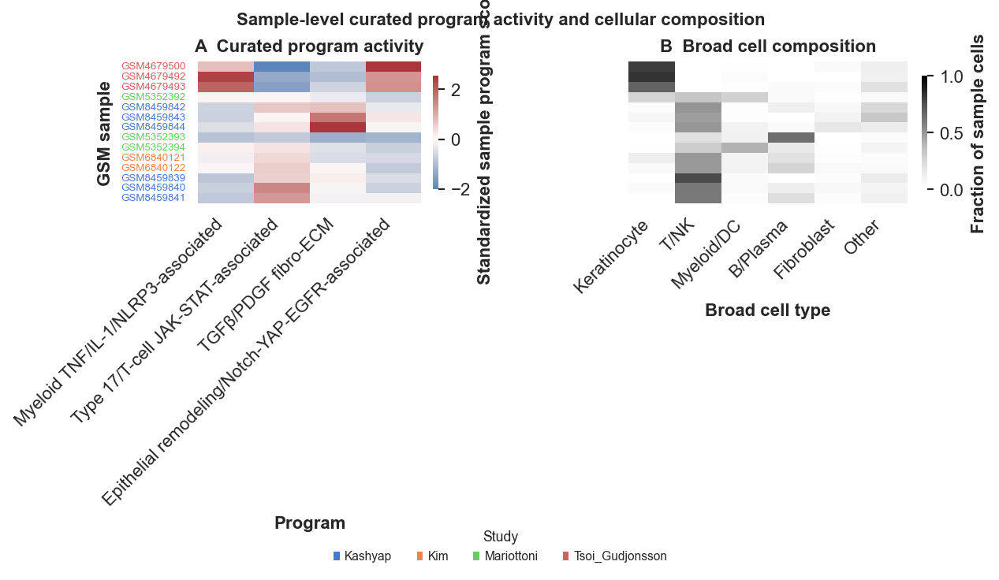

In [80]:
path_score_cols = []
for pname, genes in gene_sets.items():
    genes_present = [g for g in genes if g in var_ref]
    if len(genes_present) < 3:
        continue

    score_name = f"{pname}_score"
    sc.tl.score_genes(
        ws_adata,
        gene_list=genes_present,
        score_name=score_name,
        use_raw=use_raw,
        random_state=SEED,
    )
    path_score_cols.append(score_name)

if len(path_score_cols) == 0:
    raise ValueError("No curated program scores could be computed; check gene names.")

path_obs = ws_adata.obs[["GSM"] + path_score_cols].copy()
sample_path_scores = path_obs.groupby("GSM", observed=False)[path_score_cols].mean()

scaler = StandardScaler()
scores_z = scaler.fit_transform(sample_path_scores.values)
scores_z_df = pd.DataFrame(scores_z, index=sample_path_scores.index, columns=path_score_cols)

col_rename = {c: c.replace("_score", "") for c in scores_z_df.columns}
scores_z_df = scores_z_df.rename(columns=col_rename)
sample_path_scores_named = sample_path_scores.rename(columns=col_rename)

highest_path = scores_z_df.idxmax(axis=1)
scores_z_df["Highest_Program"] = highest_path
scores_z_df = scores_z_df.sort_values("Highest_Program")
scores_z_plot = scores_z_df.drop(columns="Highest_Program")

sample_broad_frac = pd.crosstab(
    ws_adata.obs["GSM"].astype(str),
    ws_adata.obs["WS_Broad_Celltype"].astype(str),
    normalize="index",
)
preferred_broad_order = [x for x in ["Keratinocyte", "T/NK", "Myeloid/DC", "B/Plasma", "Fibroblast", "Other"] if x in sample_broad_frac.columns]
sample_broad_frac = sample_broad_frac.reindex(columns=preferred_broad_order)
sample_broad_plot = sample_broad_frac.reindex(scores_z_plot.index)

sample_study_for_path = (
    ws_adata.obs[["GSM", "Study"]]
    .drop_duplicates("GSM")
    .set_index("GSM")["Study"]
    .astype(str)
)
study_order_path = sorted(sample_study_for_path.dropna().unique().tolist())
study_palette_path = dict(zip(study_order_path, sns.color_palette("muted", n_colors=max(1, len(study_order_path)))))

fig4 = plt.figure(figsize=(7.8, 4.2), constrained_layout=True)
gs4 = fig4.add_gridspec(1, 2, width_ratios=[1.0, 1.25], wspace=0.16)
ax4a = fig4.add_subplot(gs4[0, 0])
ax4b = fig4.add_subplot(gs4[0, 1])

sns.heatmap(
    scores_z_plot,
    cmap="vlag",
    center=0,
    ax=ax4a,
    cbar_kws={"label": "Standardized sample program score", "shrink": 0.8},
)
ax4a.set_title("A  Curated program activity", fontweight="bold", fontsize=10)
ax4a.set_xlabel("Program", fontweight="bold", fontsize=10)
ax4a.set_ylabel("GSM sample", fontweight="bold", fontsize=10)
ax4a.tick_params(axis="y", labelsize=6)
plt.setp(ax4a.get_xticklabels(), rotation=45, ha="right")

for tick in ax4a.get_yticklabels():
    gsm = tick.get_text()
    tick.set_color(study_palette_path.get(sample_study_for_path.get(gsm, ""), "black"))

sns.heatmap(
    sample_broad_plot,
    cmap="Greys",
    vmin=0,
    vmax=1,
    ax=ax4b,
    yticklabels=False,
    cbar_kws={"label": "Fraction of sample cells", "shrink": 0.8},
)
ax4b.set_title("B  Broad cell composition", fontweight="bold", fontsize=10)
ax4b.set_xlabel("Broad cell type", fontweight="bold", fontsize=10)
ax4b.set_ylabel("")
plt.setp(ax4b.get_xticklabels(), rotation=45, ha="right")

if study_palette_path:
    handles = [Patch(facecolor=study_palette_path[s], edgecolor="none", label=s) for s in study_order_path]
    fig4.legend(
        handles=handles,
        title="Study",
        frameon=False,
        fontsize=7,
        title_fontsize=8,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.07),
        ncol=min(4, len(handles)),
    )

fig4.suptitle("Sample-level curated program activity and cellular composition", fontweight="bold")
fig4.savefig(FIG_DIR / "figure-9.pdf", bbox_inches="tight")
plt.show()


In [81]:
highest = scores_z_df["Highest_Program"].copy()
highest_counts = highest.value_counts()

rows = []
for gsm in scores_z_plot.index:
    r = scores_z_plot.loc[gsm].sort_values(ascending=False)
    top2 = r.head(2)
    rows.append({
        "GSM": gsm,
        "Study": sample_study_for_path.get(gsm, "Unknown"),
        "Highest_Standardized_Program": highest.loc[gsm],
        "Top_Score": float(top2.iloc[0]) if len(top2) else np.nan,
        "Second_Score": float(top2.iloc[1]) if len(top2) > 1 else np.nan,
        "Top2": "; ".join([f"{k}:{v:.3f}" for k, v in top2.items()]),
        "All_Scores_Below_Zero": bool((r < 0).all()),
    })
per_sample = pd.DataFrame(rows).set_index("GSM")

top_by_path = {p: scores_z_plot[p].sort_values(ascending=False).head(5) for p in scores_z_plot.columns}


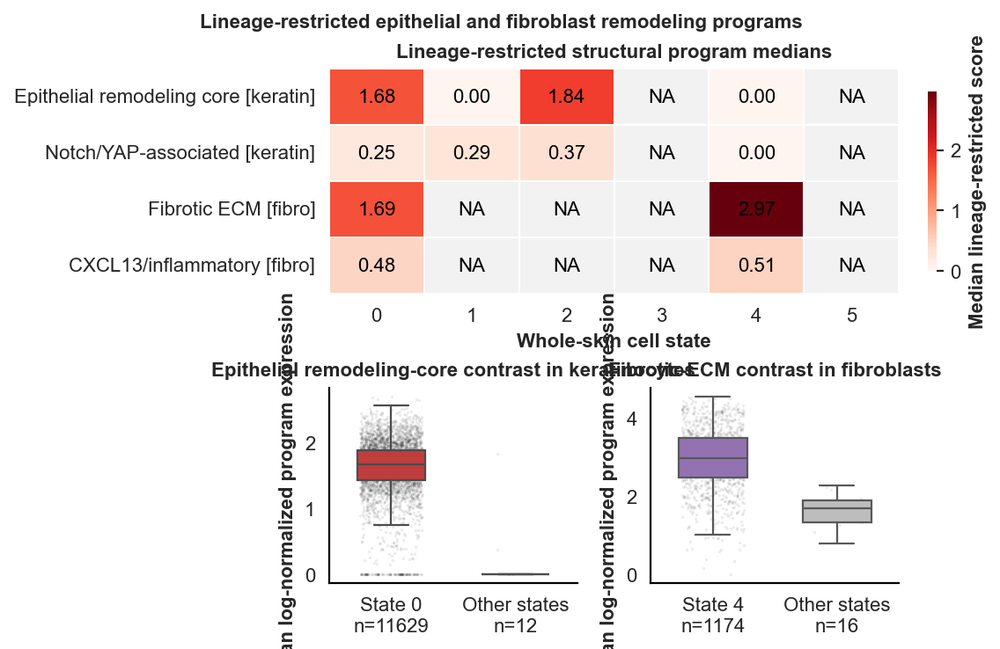

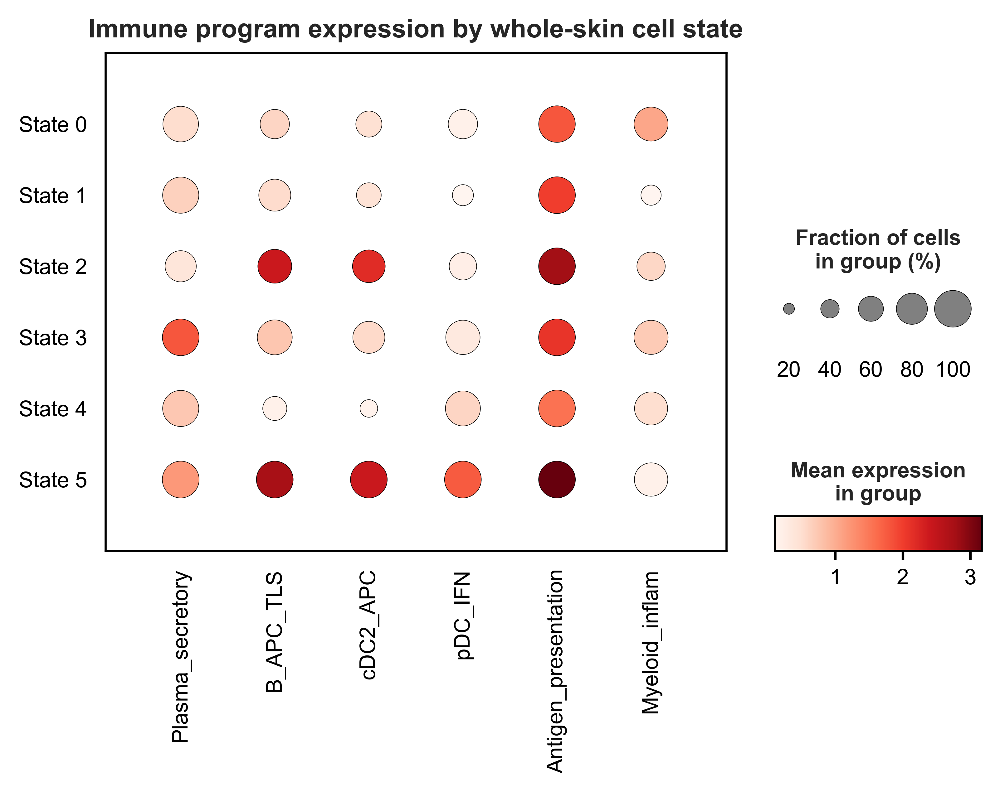

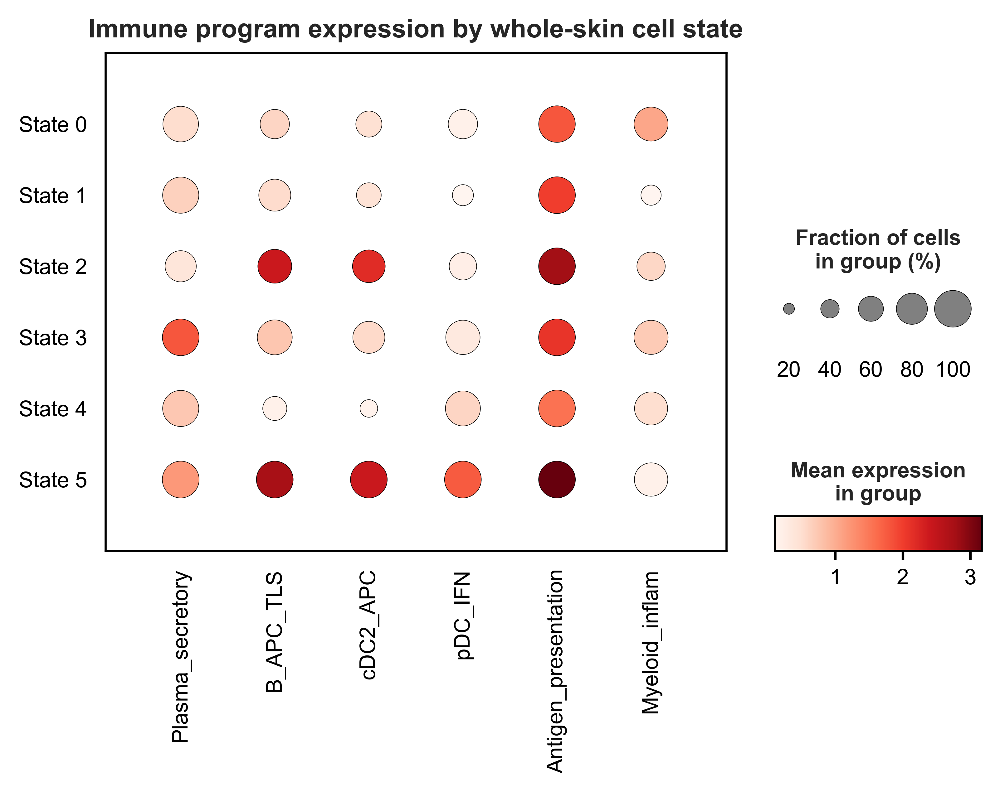

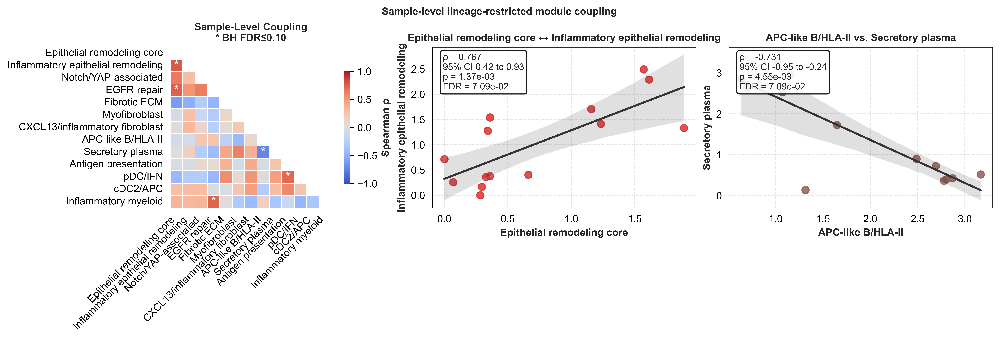

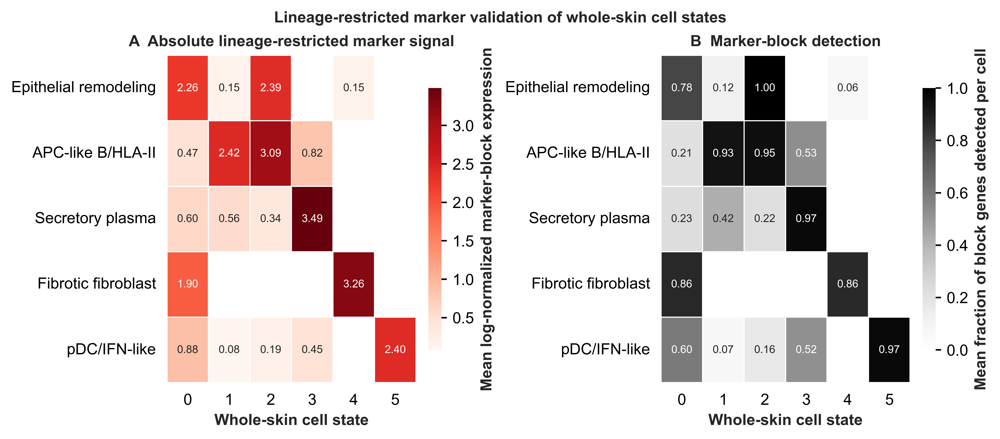

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
import scanpy as sc


sample_col = "GSM"
major_ct_col = "cell_type_major"
et_key = "WS_Endotype" if "WS_Endotype" in ws_adata.obs.columns else cluster_key

assert et_key in ws_adata.obs.columns, f"{et_key} not found in ws_adata.obs"
assert sample_col in ws_adata.obs.columns, f"{sample_col} not found in ws_adata.obs"
assert major_ct_col in ws_adata.obs.columns, f"{major_ct_col} not found in ws_adata.obs"

def _sort_key(x):
    sx = str(x)
    return (0, int(sx)) if sx.isdigit() else (1, sx)

def local_zscore(df):
    out = (df - df.mean()) / df.std(ddof=1)
    return out.replace([np.inf, -np.inf], np.nan).fillna(0.0)

def bh_fdr(pvals):
    pvals = np.asarray(pvals, dtype=float)
    n = pvals.size
    out = np.full(n, np.nan)
    if n == 0:
        return out
    order = np.argsort(np.where(np.isnan(pvals), np.inf, pvals))
    ranked = pvals[order]
    finite = np.isfinite(ranked)
    if finite.sum() == 0:
        return out
    idx = np.where(finite)[0]
    pv = ranked[idx]
    m = pv.size
    q = pv * m / np.arange(1, m + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out[order[idx]] = q
    return out

PROGRAM_DISPLAY_NAMES = {
    "Tunnel_core": "Epithelial remodeling core",
    "Tunnel_inflamed": "Inflammatory epithelial remodeling",
    "Notch_YAP": "Notch/YAP-associated",
    "EGFR_repair": "EGFR repair",
    "Fibro_fibrotic": "Fibrotic ECM",
    "Fibro_myofibro": "Myofibroblast",
    "Fibro_TLS_inflam": "CXCL13/inflammatory fibroblast",
    "B_APC_TLS": "APC-like B/HLA-II",
    "Plasma_secretory": "Secretory plasma",
    "pDC_IFN": "pDC/IFN",
    "cDC2_APC": "cDC2/APC",
    "Myeloid_inflam": "Inflammatory myeloid",
    "Antigen_presentation": "Antigen presentation",
}

def nice_prog_name(x):
    return PROGRAM_DISPLAY_NAMES.get(str(x), str(x).replace("_", " "))

def fmt_pair_title(a, b, positive=True):
    joiner = "↔" if positive else "vs."
    return f"{nice_prog_name(a)} {joiner} {nice_prog_name(b)}"

def bootstrap_spearman_ci(x, y, n_boot=2000, seed=0):
    tmp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    if tmp.shape[0] < 6:
        return (np.nan, np.nan)
    xv = tmp["x"].to_numpy(dtype=float)
    yv = tmp["y"].to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(xv), len(xv))
        xb = xv[idx]
        yb = yv[idx]
        if np.unique(xb).size < 2 or np.unique(yb).size < 2:
            continue
        r, _ = spearmanr(xb, yb)
        if np.isfinite(r):
            boots.append(float(r))
    if len(boots) < 100:
        return (np.nan, np.nan)
    return tuple(np.percentile(boots, [2.5, 97.5]))

def add_corr_annotation(ax, rho, p, fdr, ci=None):
    lines = [f"ρ = {rho:.3f}"]
    if ci is not None and np.all(np.isfinite(ci)):
        lines.append(f"95% CI {ci[0]:.2f} to {ci[1]:.2f}")
    lines.append(f"p = {p:.2e}")
    if pd.notna(fdr):
        lines.append(f"FDR = {fdr:.2e}")
    txt = "\n".join(lines)
    ax.text(
        0.04, 0.96, txt,
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="black", alpha=0.9),
    )

def get_matrix_and_varnames(adata):
    if adata.raw is not None:
        return adata.raw.X, pd.Index(adata.raw.var_names)
    return adata.X, pd.Index(adata.var_names)

def genes_present_in_adata(adata, genes):
    _, var_names = get_matrix_and_varnames(adata)
    vset = set(map(str, var_names))
    return [g for g in genes if g in vset]

def compute_program_scores(adata, gene_sets):
    X, var_names = get_matrix_and_varnames(adata)
    var_to_idx = {str(g): i for i, g in enumerate(var_names)}
    out = {}
    used = {}
    for name, genes in gene_sets.items():
        keep = [g for g in genes if g in var_to_idx]
        used[name] = keep
        if len(keep) == 0:
            out[name] = np.full(adata.n_obs, np.nan)
            continue
        idx = [var_to_idx[g] for g in keep]
        vals = np.asarray(X[:, idx].mean(axis=1)).ravel()
        out[name] = vals
    df = pd.DataFrame(out)
    df.index = pd.RangeIndex(adata.n_obs)
    return df, used

def mean_block_score_by_group(adata, genes, group_values):
    X, var_names = get_matrix_and_varnames(adata)
    var_to_idx = {str(g): i for i, g in enumerate(var_names)}
    keep = [g for g in genes if g in var_to_idx]
    if len(keep) == 0:
        return pd.Series(dtype=float)
    idx = [var_to_idx[g] for g in keep]
    vals = np.asarray(X[:, idx].mean(axis=1)).ravel()
    tmp = pd.DataFrame({
        "_group": pd.Series(group_values).astype(str).values,
        "_score": vals
    })
    return tmp.groupby("_group", observed=False)["_score"].mean()


SCAN_PROGRAMS = {
    "Tunnel_core": ["KRT14","KRT5","SOX9","KLF5","GATA3","ITGA6","COL17A1","LAMC2","TACSTD2","DSP","PERP"],
    "Tunnel_inflamed": ["KRT6A","KRT6B","KRT16","KRT17","S100A8","S100A9","IL36G","CXCL1","CXCL2","CXCL8","CCL20","SFN"],
    "Notch_YAP": ["NCSTN","PSENEN","PSEN1","NOTCH1","NOTCH2","JAG1","JAG2","RBPJ","HES1","MAML1","YAP1","WWTR1","TEAD1","TEAD4","CTGF","CYR61"],
    "EGFR_repair": ["EGFR","ERBB2","AREG","EREG","HBEGF","TGFA","KRT17","KRT6A"],

    "Fibro_fibrotic": ["COL1A1","COL1A2","COL3A1","COL5A1","COL6A1","COL6A3","POSTN","THBS1","DCN","LUM","SPARC","SFRP4"],
    "Fibro_myofibro": ["ACTA2","TAGLN","MYLK","CTGF","SERPINE1","LOX","TGFB1","TGFBR2","SMAD3"],
    "Fibro_TLS_inflam": ["CXCL13","CXCL12","CCL19","CCL2","IL6","IL33","VCAM1","ICAM1","CCL21"],

    "B_APC_TLS": ["MS4A1","CD79A","CD79B","BANK1","CD74","HLA-DRA","HLA-DPA1","HLA-DPB1","HLA-DQA1","HLA-DQB1"],
    "Plasma_secretory": ["XBP1","PRDM1","JCHAIN","MZB1","DERL3","FKBP11","SEC11C","SSR4","SSR3","HSP90B1","PRDX4","IGKC","IGLC2"],

    "pDC_IFN": ["IRF7","TCF4","IL3RA","PLD4","GZMB","IFI6","IFITM1","SERPINF1","TSPAN13","CLEC4C"],
    "cDC2_APC": ["FCER1A","CD1C","CLEC10A","HLA-DRA","HLA-DPA1","HLA-DPB1","CCR7","LAMP3"],
    "Myeloid_inflam": ["IL1B","TNF","CXCL1","CXCL2","CXCL8","NLRP3","PYCARD","CASP1","S100A8","S100A9","PTGS2"],
    "Antigen_presentation": ["HLA-DRA","HLA-DRB1","CD74","B2M","HLA-A","HLA-B","TAP1","PSMB8"],
}
SCAN_PROGRAMS = {
    k: v for k, v in SCAN_PROGRAMS.items()
    if len(genes_present_in_adata(ws_adata, v)) >= 3
}
programs_to_sync = list(SCAN_PROGRAMS.keys())


scores_df, genes_used = compute_program_scores(ws_adata, SCAN_PROGRAMS)
assert scores_df.shape[0] == ws_adata.n_obs, f"Program score rows ({scores_df.shape[0]}) != ws_adata.n_obs ({ws_adata.n_obs})"

for prog in programs_to_sync:
    ws_adata.obs[prog] = np.asarray(scores_df[prog]).ravel()

ws_plot_df = ws_adata.obs[[sample_col, major_ct_col, et_key] + programs_to_sync].copy()
ws_plot_df[sample_col] = ws_plot_df[sample_col].astype(str)
ws_plot_df[major_ct_col] = ws_plot_df[major_ct_col].astype(str)
ws_plot_df[et_key] = ws_plot_df[et_key].astype(str)

et_order = sorted(ws_plot_df[et_key].dropna().unique().tolist(), key=_sort_key)
ws_plot_df["_et_plot"] = pd.Categorical(ws_plot_df[et_key], categories=et_order, ordered=True)
ws_adata.obs["_et_plot"] = pd.Categorical(ws_adata.obs[et_key].astype(str), categories=et_order, ordered=True)


ws_adata.obs["Endotype_Label"] = "State " + ws_adata.obs["_et_plot"].astype(str)
clear_et_order = ["State " + str(x) for x in et_order]
ws_adata.obs["Endotype_Label"] = pd.Categorical(ws_adata.obs["Endotype_Label"], categories=clear_et_order, ordered=True)

keratin_cts = [x for x in ws_plot_df[major_ct_col].unique().tolist() if "Keratinocyte" in str(x)]

custom_pal = {
    et: (
        "#D62728" if str(et) == "0"
        else "#8C564B" if str(et) == "5"
        else "#2CA02C" if str(et) in ["2", "6"]
        else "#9467BD" if str(et) == "4"
        else "#BDBDBD"
    )
    for et in et_order
}


plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "figure.titlesize": 10,
    "figure.titleweight": "bold",
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.linewidth": 1.0,
    "grid.alpha": 0.0,
})


module_sources = {}

def add_module(cell_types, prog):
    if prog not in ws_plot_df.columns:
        return
    sub = ws_plot_df.loc[ws_plot_df[major_ct_col].isin(cell_types), [sample_col, prog]].copy()
    if sub.shape[0] == 0:
        return
    s = sub.groupby(sample_col, observed=False)[prog].mean()
    if s.notna().sum() >= 3:
        module_sources[prog] = s

for prog in ["Tunnel_core", "Tunnel_inflamed", "Notch_YAP", "EGFR_repair"]:
    if prog in ws_plot_df.columns:
        add_module(keratin_cts, prog)

for prog in ["Fibro_fibrotic", "Fibro_myofibro", "Fibro_TLS_inflam"]:
    if prog in ws_plot_df.columns:
        add_module(["Fibroblasts"], prog)

for prog in ["B_APC_TLS", "Plasma_secretory", "Antigen_presentation"]:
    if prog in ws_plot_df.columns:
        add_module(["B/Plasma Cells"], prog)

for prog in ["pDC_IFN", "cDC2_APC", "Myeloid_inflam", "Antigen_presentation"]:
    if prog in ws_plot_df.columns:
        add_module(["Myeloid / Dendritic Cells"], prog)

module_mat = pd.DataFrame(module_sources).sort_index()

corr_rows = []
if module_mat.shape[1] >= 2:
    for i, a in enumerate(module_mat.columns):
        for b in module_mat.columns[i + 1:]:
            dfc = module_mat[[a, b]].dropna()
            if dfc.shape[0] < 6 or dfc[a].nunique() < 2 or dfc[b].nunique() < 2:
                continue
            rho, p = spearmanr(dfc[a], dfc[b])
            corr_rows.append({
                "Prog1": a,
                "Prog2": b,
                "rho": float(rho),
                "pvalue": float(p),
                "n": int(dfc.shape[0]),
            })

corr_pairs = pd.DataFrame(corr_rows)
if corr_pairs.shape[0]:
    corr_pairs["fdr"] = bh_fdr(corr_pairs["pvalue"].values)
    corr_pairs = corr_pairs.sort_values(["fdr", "rho"], ascending=[True, False]).reset_index(drop=True)

corr_mat = module_mat.corr(method="spearman") if module_mat.shape[1] >= 2 else pd.DataFrame()

pos_hits = corr_pairs.loc[corr_pairs["rho"] > 0].sort_values(["fdr", "rho"], ascending=[True, False]) if corr_pairs.shape[0] else pd.DataFrame()
neg_hits = corr_pairs.loc[corr_pairs["rho"] < 0].sort_values(["fdr", "rho"], ascending=[True, True]) if corr_pairs.shape[0] else pd.DataFrame()

pos_row = pos_hits.iloc[0] if pos_hits.shape[0] else (corr_pairs.sort_values("rho", ascending=False).iloc[0] if corr_pairs.shape[0] else None)
neg_row = neg_hits.iloc[0] if neg_hits.shape[0] else (corr_pairs.sort_values("rho", ascending=True).iloc[0] if corr_pairs.shape[0] else None)


structural_specs = [
    ("Tunnel_core", "Epithelial remodeling core [keratin]", ws_plot_df[major_ct_col].isin(keratin_cts)),
    ("Notch_YAP", "Notch/YAP-associated [keratin]", ws_plot_df[major_ct_col].isin(keratin_cts)),
    ("Fibro_fibrotic", "Fibrotic ECM [fibro]", ws_plot_df[major_ct_col] == "Fibroblasts"),
    ("Fibro_TLS_inflam", "CXCL13/inflammatory [fibro]", ws_plot_df[major_ct_col] == "Fibroblasts"),
]

median_mat = pd.DataFrame(index=[x[1] for x in structural_specs], columns=et_order, dtype=float)
count_mat = pd.DataFrame(index=[x[1] for x in structural_specs], columns=et_order, dtype=float)

for prog, label, mask in structural_specs:
    sub = ws_plot_df.loc[mask, ["_et_plot", prog]].dropna().copy()
    for et in et_order:
        vals = sub.loc[sub["_et_plot"] == et, prog]
        count_mat.loc[label, et] = vals.shape[0]
        median_mat.loc[label, et] = vals.median() if vals.shape[0] > 0 else np.nan


fig10 = plt.figure(figsize=(7, 4.5), constrained_layout=True)
gs = fig10.add_gridspec(2, 2, height_ratios=[1.15, 1], width_ratios=[1, 1])

ax10a = fig10.add_subplot(gs[0, :])
ax10b = fig10.add_subplot(gs[1, 0])
ax10c = fig10.add_subplot(gs[1, 1])


cmap = sns.color_palette("Reds", as_cmap=True)
ax10a.set_facecolor("#F2F2F2")
sns.heatmap(
    median_mat,
    mask=median_mat.isna(),
    cmap=cmap,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Median lineage-restricted score", "shrink": 0.8},
    ax=ax10a,
    annot=False,
)

for i, rowlab in enumerate(median_mat.index):
    for j, et in enumerate(median_mat.columns):
        med = median_mat.loc[rowlab, et]
        txt = f"{med:.2f}" if pd.notna(med) else "NA"
        ax10a.text(
            j + 0.5, i + 0.5, txt,
            ha="center", va="center",
            color="black"
        )

ax10a.set_title("Lineage-restricted structural program medians", fontweight="bold")
ax10a.set_xlabel("Whole-skin cell state", fontweight="bold")
ax10a.set_ylabel("")
plt.setp(ax10a.get_xticklabels(), rotation=0)
plt.setp(ax10a.get_yticklabels(), rotation=0)


df_tc = ws_plot_df.loc[ws_plot_df[major_ct_col].isin(keratin_cts), ["_et_plot", "Tunnel_core"]].dropna().copy()
df_tc["Contrast"] = np.where(df_tc["_et_plot"].astype(str) == "0", "State 0", "Other states")
order_contrast = ["State 0", "Other states"]
pal_contrast_tc = {"State 0": "#D62728", "Other states": "#BDBDBD"}

sns.boxplot(
    data=df_tc,
    x="Contrast",
    y="Tunnel_core",
    order=order_contrast,
    palette=pal_contrast_tc,
    width=0.55,
    showfliers=False,
    linewidth=1.0,
    ax=ax10b,
)
sns.stripplot(
    data=df_tc.sample(min(4000, df_tc.shape[0]), random_state=0) if df_tc.shape[0] > 4000 else df_tc,
    x="Contrast",
    y="Tunnel_core",
    order=order_contrast,
    color="black",
    alpha=0.08,
    size=1.5,
    jitter=0.25,
    ax=ax10b,
    zorder=1,
)
n_et0 = (df_tc["Contrast"] == "State 0").sum()
n_oth = (df_tc["Contrast"] == "Other states").sum()
ax10b.set_xticklabels([f"State 0\nn={n_et0}", f"Other states\nn={n_oth}"])
ax10b.set_title("Epithelial remodeling-core contrast in keratinocytes", fontweight="bold")
ax10b.set_xlabel("")
ax10b.set_ylabel("Mean log-normalized program expression", fontweight="bold")
ax10b.spines["top"].set_visible(False)
ax10b.spines["right"].set_visible(False)


df_ff = ws_plot_df.loc[ws_plot_df[major_ct_col] == "Fibroblasts", ["_et_plot", "Fibro_fibrotic"]].dropna().copy()
df_ff["Contrast"] = np.where(df_ff["_et_plot"].astype(str) == "4", "State 4", "Other states")
pal_contrast_ff = {"State 4": "#9467BD", "Other states": "#BDBDBD"}

sns.boxplot(
    data=df_ff,
    x="Contrast",
    y="Fibro_fibrotic",
    order=["State 4", "Other states"],
    palette=pal_contrast_ff,
    width=0.55,
    showfliers=False,
    linewidth=1.0,
    ax=ax10c,
)
sns.stripplot(
    data=df_ff.sample(min(4000, df_ff.shape[0]), random_state=0) if df_ff.shape[0] > 4000 else df_ff,
    x="Contrast",
    y="Fibro_fibrotic",
    order=["State 4", "Other states"],
    color="black",
    alpha=0.08,
    size=1.5,
    jitter=0.25,
    ax=ax10c,
    zorder=1,
)
n_et4 = (df_ff["Contrast"] == "State 4").sum()
n_oth_f = (df_ff["Contrast"] == "Other states").sum()
ax10c.set_xticklabels([f"State 4\nn={n_et4}", f"Other states\nn={n_oth_f}"])
ax10c.set_title("Fibrotic-ECM contrast in fibroblasts", fontweight="bold")
ax10c.set_xlabel("")
ax10c.set_ylabel("Mean log-normalized program expression", fontweight="bold")
ax10c.spines["top"].set_visible(False)
ax10c.spines["right"].set_visible(False)

fig10.suptitle("Lineage-restricted epithelial and fibroblast remodeling programs", fontweight="bold")
fig10.savefig(FIG_DIR / "figure-10-structural-niches.pdf", bbox_inches="tight", dpi=300)
plt.show()


immune_progs = [
    "Plasma_secretory", "B_APC_TLS", "cDC2_APC",
    "pDC_IFN", "Antigen_presentation", "Myeloid_inflam"
]
immune_progs = [x for x in immune_progs if x in ws_adata.obs.columns]

sc.settings.set_figure_params(dpi=300, facecolor="white", vector_friendly=True, fontsize=10)
dp = sc.pl.dotplot(
    ws_adata,
    immune_progs,
    groupby="Endotype_Label",
    categories_order=clear_et_order,
    cmap="Reds",
    show=False,
    return_fig=True,
    title="Immune program expression by whole-skin cell state",
    figsize=(6, 3.5)
)
dp.savefig(FIG_DIR / "figure-11-immune-dotplot.pdf", bbox_inches="tight")
dp.show()

et_immune_mean = ws_plot_df.groupby("_et_plot", observed=False)[immune_progs].mean()


fig12, (ax_corr, ax_scat1, ax_scat2) = plt.subplots(1, 3, figsize=(13.5, 4.5), constrained_layout=True)

if corr_mat.shape[0] >= 2:
    mask = np.triu(np.ones_like(corr_mat, dtype=bool))
    corr_annot = np.full(corr_mat.shape, "", dtype=object)
    if corr_pairs.shape[0]:
        for _, row in corr_pairs.iterrows():
            i = corr_mat.index.get_loc(row["Prog1"])
            j = corr_mat.columns.get_loc(row["Prog2"])
            rr, cc = (j, i) if j > i else (i, j)
            if rr > cc and np.isfinite(row["fdr"]) and row["fdr"] <= 0.10:
                corr_annot[rr, cc] = "*"
    corr_mat_display = corr_mat.rename(
        index={x: nice_prog_name(x) for x in corr_mat.index},
        columns={x: nice_prog_name(x) for x in corr_mat.columns},
    )
    sns.heatmap(
        corr_mat_display,
        mask=mask,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=.5,
        annot=corr_annot,
        fmt="",
        annot_kws={"fontsize": 11, "fontweight": "bold"},
        cbar_kws={"shrink": .7, "label": "Spearman ρ"},
        ax=ax_corr,
    )
    ax_corr.set_title("Sample-Level Coupling\n* BH FDR≤0.10", fontweight="bold")
    ax_corr.set_xlabel("")
    ax_corr.set_ylabel("")
    plt.setp(ax_corr.get_xticklabels(), rotation=45, ha="right")
else:
    ax_corr.axis("off")
    ax_corr.set_title("No valid module correlations", fontweight="bold")

if pos_row is not None:
    a, b = pos_row["Prog1"], pos_row["Prog2"]
    dfp = module_mat[[a, b]].dropna()
    sns.regplot(
        data=dfp,
        x=a,
        y=b,
        ax=ax_scat1,
        scatter_kws={"s": 50, "alpha": 0.8, "color": "#D62728"},
        line_kws={"color": "#333333", "linewidth": 2},
    )
    ax_scat1.set_title(fmt_pair_title(a, b, positive=True), fontweight="bold")
    ax_scat1.set_xlabel(nice_prog_name(a), fontweight="bold")
    ax_scat1.set_ylabel(nice_prog_name(b), fontweight="bold")
    ax_scat1.grid(True, linestyle="--", alpha=0.5)
    ci_pos = bootstrap_spearman_ci(dfp[a], dfp[b], seed=SEED + 101)
    add_corr_annotation(ax_scat1, pos_row["rho"], pos_row["pvalue"], pos_row["fdr"], ci=ci_pos)
else:
    ax_scat1.axis("off")

if neg_row is not None:
    a, b = neg_row["Prog1"], neg_row["Prog2"]
    dfn = module_mat[[a, b]].dropna()
    sns.regplot(
        data=dfn,
        x=a,
        y=b,
        ax=ax_scat2,
        scatter_kws={"s": 50, "alpha": 0.8, "color": "#8C564B"},
        line_kws={"color": "#333333", "linewidth": 2},
    )
    ax_scat2.set_title(fmt_pair_title(a, b, positive=False), fontweight="bold")
    ax_scat2.set_xlabel(nice_prog_name(a), fontweight="bold")
    ax_scat2.set_ylabel(nice_prog_name(b), fontweight="bold")
    ax_scat2.grid(True, linestyle="--", alpha=0.5)
    ci_neg = bootstrap_spearman_ci(dfn[a], dfn[b], seed=SEED + 102)
    add_corr_annotation(ax_scat2, neg_row["rho"], neg_row["pvalue"], neg_row["fdr"], ci=ci_neg)
else:
    ax_scat2.axis("off")

fig12.suptitle("Sample-level lineage-restricted module coupling", fontweight="bold")
fig12.savefig(FIG_DIR / "figure-12-macro-polarization.pdf", bbox_inches="tight")
plt.show()

sig_corr = corr_pairs.loc[corr_pairs["fdr"] <= 0.10].copy() if corr_pairs.shape[0] else pd.DataFrame()
top_pos = sig_corr.loc[sig_corr["rho"] > 0].sort_values(["fdr", "rho"], ascending=[True, False]).head(5)
top_neg = sig_corr.loc[sig_corr["rho"] < 0].sort_values(["fdr", "rho"], ascending=[True, True]).head(5)


marker_group_specs = {
    "Epithelial remodeling": {
        "genes": ["KLF5", "TACSTD2", "PERP", "DSP", "S100A8", "S100A9", "YAP1", "PSENEN"],
        "mask": ws_plot_df[major_ct_col].isin(keratin_cts).values,
        "lineage": "Keratinocytes",
    },
    "APC-like B/HLA-II": {
        "genes": ["MS4A1", "CD79A", "BANK1", "HLA-DRA", "HLA-DPA1", "HLA-DPB1", "HLA-DQB1", "CD74"],
        "mask": (ws_plot_df[major_ct_col] == "B/Plasma Cells").values,
        "lineage": "B/Plasma",
    },
    "Secretory plasma": {
        "genes": ["XBP1", "FKBP11", "DERL3", "SEC11C", "SSR4", "PRDM1"],
        "mask": (ws_plot_df[major_ct_col] == "B/Plasma Cells").values,
        "lineage": "B/Plasma",
    },
    "Fibrotic fibroblast": {
        "genes": ["COL1A1", "COL1A2", "DCN", "LUM", "SPARC", "SERPINE1"],
        "mask": (ws_plot_df[major_ct_col] == "Fibroblasts").values,
        "lineage": "Fibroblasts",
    },
    "pDC/IFN-like": {
        "genes": ["TCF4", "IRF7", "IL3RA", "PLD4", "TSPAN13"],
        "mask": (ws_plot_df[major_ct_col] == "Myeloid / Dendritic Cells").values,
        "lineage": "Myeloid/DC",
    },
}

Xsrc, vnames = get_matrix_and_varnames(ws_adata)
vset = set(map(str, vnames))
mean_marker_mat = pd.DataFrame(index=marker_group_specs.keys(), columns=et_order, dtype=float)
detect_marker_mat = pd.DataFrame(index=marker_group_specs.keys(), columns=et_order, dtype=float)
marker_count_mat = pd.DataFrame(index=marker_group_specs.keys(), columns=et_order, dtype=float)
marker_genes_used = {}

for grp, spec in marker_group_specs.items():
    genes = [g for g in spec["genes"] if g in vset]
    marker_genes_used[grp] = genes
    if len(genes) == 0:
        continue

    sub = ws_adata[spec["mask"]].copy()
    if sub.n_obs == 0:
        continue

    Xg, vg = get_matrix_and_varnames(sub)
    var_to_idx = {str(g): i for i, g in enumerate(vg)}
    idx = [var_to_idx[g] for g in genes]
    vals = Xg[:, idx]
    if hasattr(vals, "toarray"):
        vals = vals.toarray()
    vals = np.asarray(vals, dtype=float)

    cell_mean = vals.mean(axis=1)
    cell_detect = (vals > 0).mean(axis=1)
    state_vals = sub.obs[et_key].astype(str).values

    for state in et_order:
        keep = state_vals == str(state)
        marker_count_mat.loc[grp, state] = int(keep.sum())
        if keep.sum() == 0:
            continue
        mean_marker_mat.loc[grp, state] = float(np.nanmean(cell_mean[keep]))
        detect_marker_mat.loc[grp, state] = float(np.nanmean(cell_detect[keep]))

fig13, (ax13a, ax13b) = plt.subplots(1, 2, figsize=(8.8, 3.8), constrained_layout=True)

sns.heatmap(
    mean_marker_mat,
    mask=mean_marker_mat.isna(),
    cmap="Reds",
    linewidths=0.5,
    linecolor="white",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7},
    cbar_kws={"label": "Mean log-normalized marker-block expression", "shrink": 0.8},
    ax=ax13a,
)
ax13a.set_title("A  Absolute lineage-restricted marker signal", fontweight="bold")
ax13a.set_xlabel("Whole-skin cell state", fontweight="bold")
ax13a.set_ylabel("")

sns.heatmap(
    detect_marker_mat,
    mask=detect_marker_mat.isna(),
    cmap="Greys",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7},
    cbar_kws={"label": "Mean fraction of block genes detected per cell", "shrink": 0.8},
    ax=ax13b,
)
ax13b.set_title("B  Marker-block detection", fontweight="bold")
ax13b.set_xlabel("Whole-skin cell state", fontweight="bold")
ax13b.set_ylabel("")

fig13.suptitle("Lineage-restricted marker validation of whole-skin cell states", fontweight="bold")
fig13.savefig(FIG_DIR / "figure-13-targeted-marker-dotplot.pdf", bbox_inches="tight")
plt.show()


De novo clustering of Whole_skin cells is used as a coarse cellular-state scaffold for the whole-lesion dataset. Because these cell-level states are lineage-enriched, lesion heterogeneity is evaluated from their sample-level mixtures together with lineage-restricted transcriptional programs, rather than by assigning each patient to a single mutually exclusive endotype.

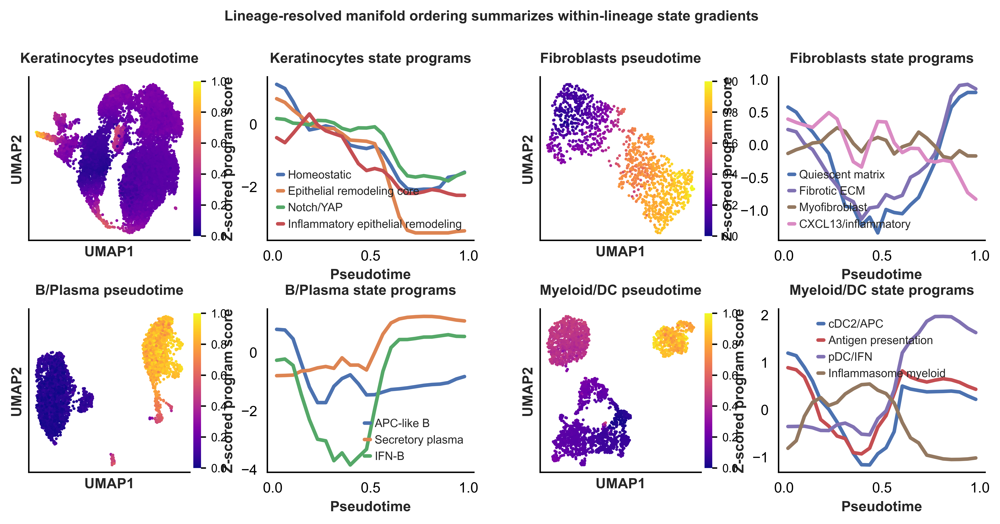

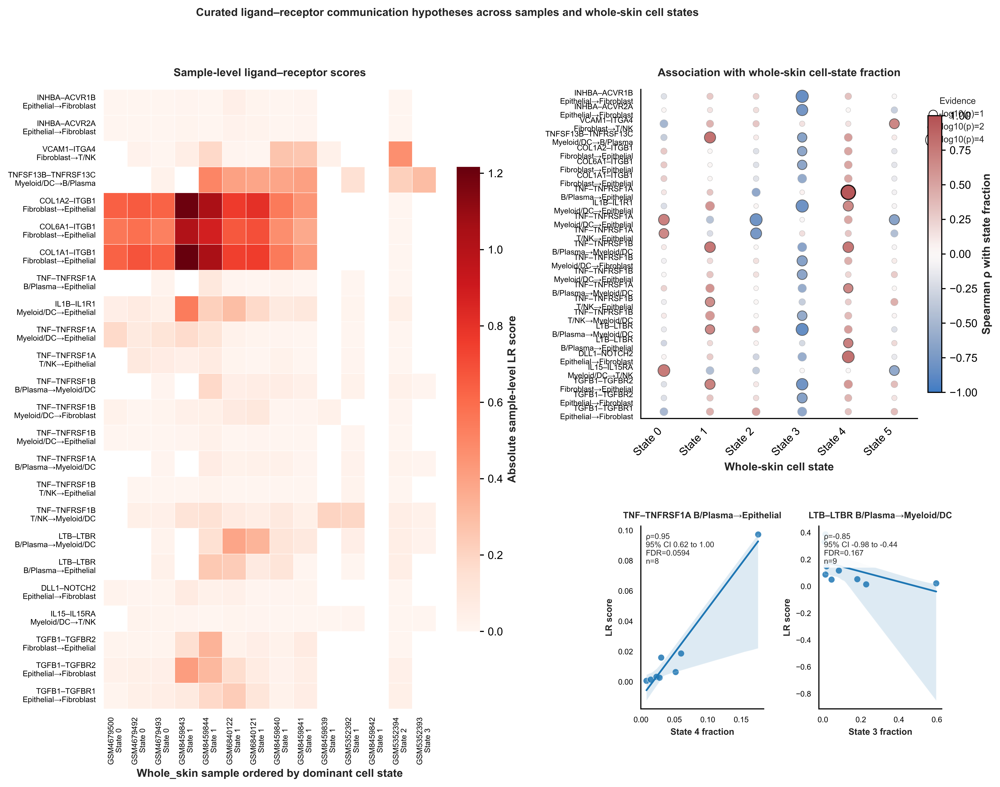

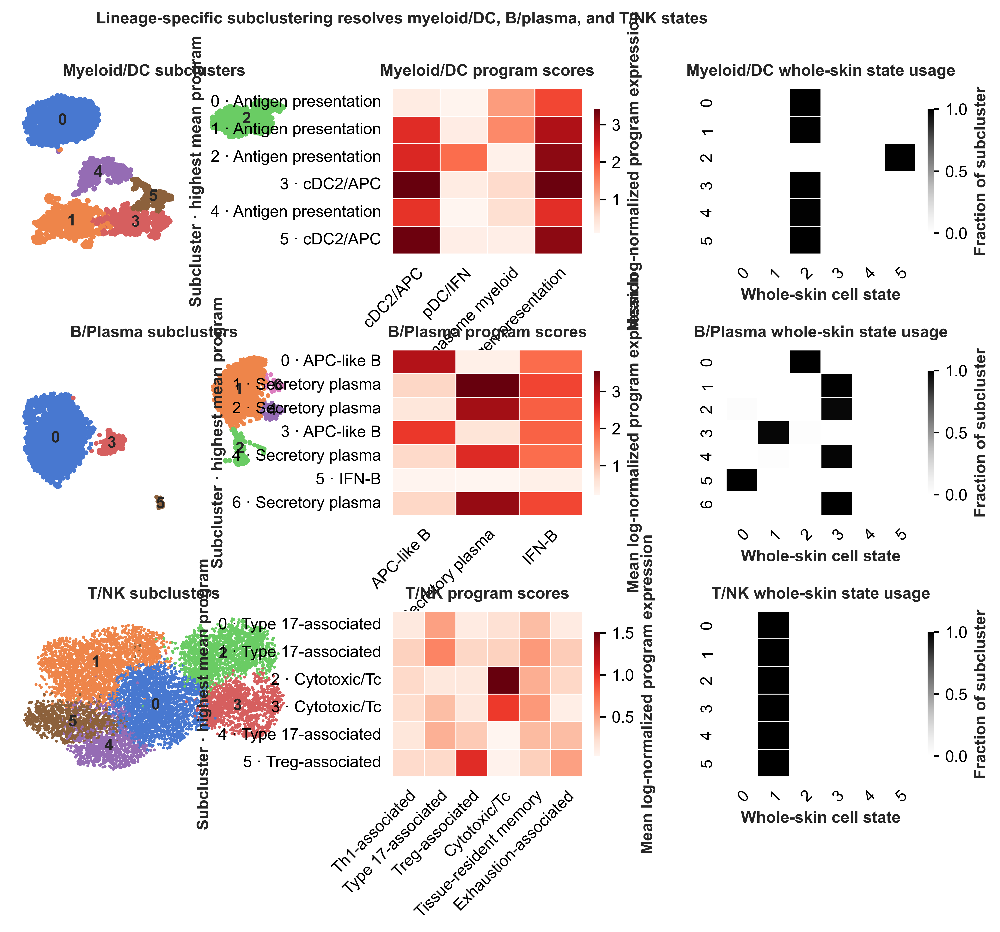

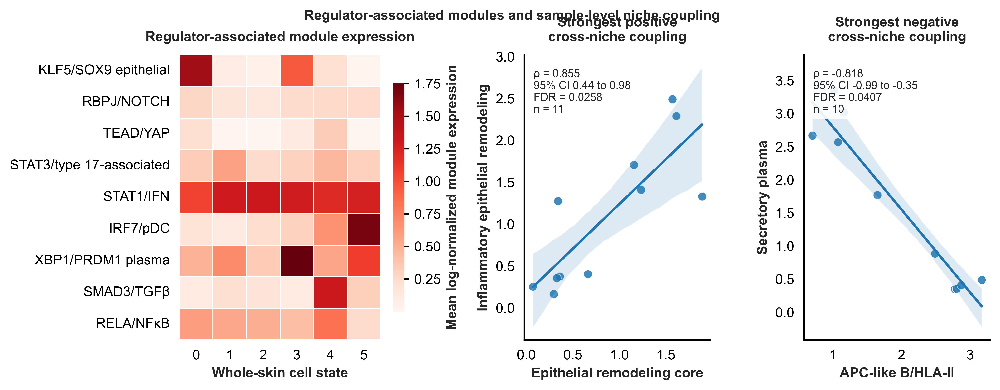

In [83]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.sparse import issparse
from scipy.stats import spearmanr


SEED = globals().get("SEED", 0)
np.random.seed(SEED)

FIG_DIR = globals().get("FIG_DIR", Path("Figures"))
FIG_DIR.mkdir(parents=True, exist_ok=True)


mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "figure.titlesize": 10,
    "figure.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

if "ws_adata" not in globals():
    if "integrated_adata" not in globals():
        raise ValueError("Need ws_adata or integrated_adata in memory.")
    if "Tissue_Fraction" not in integrated_adata.obs.columns:
        raise ValueError("Cannot recreate ws_adata because Tissue_Fraction is missing.")
    ws_adata = integrated_adata[integrated_adata.obs["Tissue_Fraction"].astype(str) == "Whole_skin"].copy()

sample_col = "GSM"
major_ct_col = "cell_type_major"
et_key = "WS_Endotype" if "WS_Endotype" in ws_adata.obs.columns else None

if et_key is None:
    tmp = ws_adata.copy()
    if "X_pca_harmony" in tmp.obsm:
        try:
            sc.pp.neighbors(tmp, use_rep="X_pca_harmony", n_neighbors=10, random_state=SEED)
        except TypeError:
            sc.pp.neighbors(tmp, use_rep="X_pca_harmony", n_neighbors=10)
    else:
        sc.pp.scale(tmp, max_value=10)
        sc.tl.pca(tmp, svd_solver="arpack", n_comps=min(50, max(2, tmp.n_vars - 1)), random_state=SEED)
        try:
            sc.pp.neighbors(tmp, use_rep="X_pca", n_neighbors=10, random_state=SEED)
        except TypeError:
            sc.pp.neighbors(tmp, use_rep="X_pca", n_neighbors=10)
    try:
        sc.tl.leiden(tmp, resolution=0.02, key_added="WS_Endotype", random_state=SEED)
    except TypeError:
        sc.tl.leiden(tmp, resolution=0.02, key_added="WS_Endotype")
    ws_adata.obs["WS_Endotype"] = tmp.obs["WS_Endotype"].astype(str).values
    et_key = "WS_Endotype"

if sample_col not in ws_adata.obs.columns:
    raise ValueError(f"{sample_col} missing from ws_adata.obs")
if major_ct_col not in ws_adata.obs.columns:
    raise ValueError(f"{major_ct_col} missing from ws_adata.obs")

ws_adata.obs[et_key] = ws_adata.obs[et_key].astype(str)
et_order = sorted(
    ws_adata.obs[et_key].unique().tolist(),
    key=lambda x: (0, int(x)) if str(x).isdigit() else (1, str(x))
)
samples = sorted(ws_adata.obs[sample_col].astype(str).unique().tolist())


def bh_fdr(pvals):
    pvals = np.asarray(pvals, dtype=float)
    out = np.full(pvals.shape, np.nan, dtype=float)
    finite = np.isfinite(pvals)
    if finite.sum() == 0:
        return out
    idx = np.where(finite)[0]
    pv = pvals[idx]
    order = np.argsort(pv)
    ranked = pv[order]
    m = len(ranked)
    q = ranked * m / np.arange(1, m + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    out[idx[order]] = q
    return out

def row_z(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy().astype(float)
    x = x.sub(x.mean(axis=1), axis=0)
    x = x.div(x.std(axis=1, ddof=1).replace(0, np.nan), axis=0)
    return x.replace([np.inf, -np.inf], np.nan).fillna(0.0)

def col_z(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy().astype(float)
    x = x.sub(x.mean(axis=0), axis=1)
    x = x.div(x.std(axis=0, ddof=1).replace(0, np.nan), axis=1)
    return x.replace([np.inf, -np.inf], np.nan).fillna(0.0)

def safe_spearman(x, y, min_n=6):
    tmp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    if tmp.shape[0] < min_n or tmp["x"].nunique() < 2 or tmp["y"].nunique() < 2:
        return np.nan, np.nan, int(tmp.shape[0])
    rho, p = spearmanr(tmp["x"], tmp["y"])
    return float(rho), float(p), int(tmp.shape[0])

def bootstrap_spearman_ci(x, y, n_boot=2000, seed=0):
    tmp = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    if tmp.shape[0] < 6:
        return (np.nan, np.nan)
    xv = tmp["x"].to_numpy(dtype=float)
    yv = tmp["y"].to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(xv), len(xv))
        xb = xv[idx]
        yb = yv[idx]
        if np.unique(xb).size < 2 or np.unique(yb).size < 2:
            continue
        rho, _ = spearmanr(xb, yb)
        if np.isfinite(rho):
            boots.append(float(rho))
    if len(boots) < 100:
        return (np.nan, np.nan)
    return tuple(np.percentile(boots, [2.5, 97.5]))

MODULE_DISPLAY = {
    "Keratin_tunnel_core": "Epithelial remodeling core",
    "Keratin_Notch_YAP": "Keratinocyte Notch/YAP-associated",
    "Keratin_tunnel_inflamed": "Inflammatory epithelial remodeling",
    "Fibro_fibrotic": "Fibrotic ECM",
    "Fibro_TLS_inflam": "CXCL13/inflammatory fibroblast",
    "B_APC_like": "APC-like B/HLA-II",
    "Plasma_secretory": "Secretory plasma",
    "pDC_IFN": "pDC/IFN",
    "cDC2_APC": "cDC2/APC",
}

def get_expr_df(adata, genes):
    genes = list(dict.fromkeys([str(g) for g in genes]))
    if len(genes) == 0:
        return pd.DataFrame(index=adata.obs_names)
    if adata.raw is not None:
        vnames = pd.Index(adata.raw.var_names.astype(str))
        keep = [g for g in genes if g in vnames]
        if len(keep) == 0:
            return pd.DataFrame(index=adata.obs_names)
        X = adata.raw[:, keep].X
    else:
        vnames = pd.Index(adata.var_names.astype(str))
        keep = [g for g in genes if g in vnames]
        if len(keep) == 0:
            return pd.DataFrame(index=adata.obs_names)
        X = adata[:, keep].X
    if issparse(X):
        X = X.toarray()
    return pd.DataFrame(np.asarray(X), index=adata.obs_names, columns=keep)

def score_gene_sets(adata, gene_sets):
    all_genes = []
    for gs in gene_sets.values():
        all_genes.extend(gs)
    expr = get_expr_df(adata, all_genes)
    out = {}
    used = {}
    for name, genes in gene_sets.items():
        keep = [g for g in genes if g in expr.columns]
        used[name] = keep
        if len(keep) == 0:
            out[name] = np.full(adata.n_obs, np.nan)
        else:
            out[name] = expr[keep].mean(axis=1).values
    return pd.DataFrame(out, index=adata.obs_names), used

def broad_group(x):
    s = str(x)
    if "Keratinocyte" in s:
        return "Keratinocyte"
    if s == "Fibroblasts":
        return "Fibroblast"
    if s == "Myeloid / Dendritic Cells":
        return "Myeloid_DC"
    if s == "B/Plasma Cells":
        return "B_Plasma"
    if s in ["T Cells", "Cytotoxic T/NK Cells"]:
        return "T_NK"
    if s == "Endothelial Cells":
        return "Endothelial"
    if s == "Mast Cells":
        return "Mast"
    if s == "Melanocytes":
        return "Melanocyte"
    return "Other"

def ensure_graph_umap(sub):
    n_neighbors = min(15, max(5, sub.n_obs - 1))
    if "X_pca_harmony" in sub.obsm:
        try:
            sc.pp.neighbors(sub, use_rep="X_pca_harmony", n_neighbors=n_neighbors, random_state=SEED)
        except TypeError:
            sc.pp.neighbors(sub, use_rep="X_pca_harmony", n_neighbors=n_neighbors)
    elif "X_pca" in sub.obsm:
        try:
            sc.pp.neighbors(sub, use_rep="X_pca", n_neighbors=n_neighbors, random_state=SEED)
        except TypeError:
            sc.pp.neighbors(sub, use_rep="X_pca", n_neighbors=n_neighbors)
    else:
        x = sub.copy()
        if "highly_variable" in x.var.columns and x.var["highly_variable"].sum() > 0:
            x = x[:, x.var["highly_variable"]].copy()
        sc.pp.scale(x, max_value=10)
        sc.tl.pca(x, svd_solver="arpack", n_comps=min(30, max(2, x.n_vars - 1)), random_state=SEED)
        try:
            sc.pp.neighbors(x, use_rep="X_pca", n_neighbors=n_neighbors, random_state=SEED)
        except TypeError:
            sc.pp.neighbors(x, use_rep="X_pca", n_neighbors=n_neighbors)
        sub.obsp["connectivities"] = x.obsp["connectivities"].copy()
        sub.obsp["distances"] = x.obsp["distances"].copy()
    try:
        sc.tl.umap(sub, random_state=SEED)
    except TypeError:
        sc.tl.umap(sub)
    return sub

def run_lineage_dpt(sub, root_genes):
    sub = ensure_graph_umap(sub)
    sc.tl.diffmap(sub)
    root_scores, _ = score_gene_sets(sub, {"root": root_genes})
    if np.isfinite(root_scores["root"]).sum() == 0:
        raise ValueError("None of the root genes were present.")
    sub.uns["iroot"] = int(np.nanargmax(root_scores["root"].values))
    sc.tl.dpt(sub, n_dcs=min(10, sub.obsm["X_diffmap"].shape[1]))
    return sub

def bin_trends(pseudotime, score_df, n_bins=24):
    pt = np.asarray(pseudotime, dtype=float)
    bins = np.linspace(float(np.nanmin(pt)), float(np.nanmax(pt)), n_bins + 1)
    bins = np.unique(bins)
    if len(bins) < 4:
        bins = np.linspace(0.0, 1.0, n_bins + 1)
    cut = pd.cut(pt, bins=bins, include_lowest=True, duplicates="drop")
    z = col_z(score_df)
    trend = z.groupby(cut, observed=False).mean()
    centers = np.array([iv.mid for iv in trend.index])
    return centers, trend

def summarize_top_markers(adata, groupby, groups, n=3):
    out = {}
    try:
        sc.tl.rank_genes_groups(adata, groupby=groupby, method="wilcoxon")
        for g in groups:
            df = sc.get.rank_genes_groups_df(adata, group=str(g)).head(n)
            out[str(g)] = ", ".join(df["names"].astype(str).tolist())
    except Exception:
        for g in groups:
            out[str(g)] = ""
    return out

def top_signed_rows(df, sign="positive", n=5, sig_only=False, fdr_cutoff=0.10):
    if df is None or df.shape[0] == 0:
        return pd.DataFrame(columns=df.columns if df is not None else [])
    out = df.copy()
    out = out[np.isfinite(out["rho"])]
    if sig_only and "fdr" in out.columns:
        out = out[np.isfinite(out["fdr"]) & (out["fdr"] <= fdr_cutoff)]
    if sign == "positive":
        out = out[out["rho"] > 0].sort_values(["fdr", "rho"], ascending=[True, False])
    else:
        out = out[out["rho"] < 0].sort_values(["fdr", "rho"], ascending=[True, True])
    return out.head(n)

def pick_best_signed_row(df, sign="positive", fdr_cutoff=0.10):
    sig = top_signed_rows(df, sign=sign, n=1, sig_only=True, fdr_cutoff=fdr_cutoff)
    if sig.shape[0] > 0:
        return sig.iloc[0]
    all_rows = top_signed_rows(df, sign=sign, n=1, sig_only=False, fdr_cutoff=fdr_cutoff)
    if all_rows.shape[0] > 0:
        return all_rows.iloc[0]
    return None


ws_obs = ws_adata.obs.copy()
ws_obs[sample_col] = ws_obs[sample_col].astype(str)
ws_obs[major_ct_col] = ws_obs[major_ct_col].astype(str)
ws_obs["_broad"] = ws_obs[major_ct_col].map(broad_group)


KER_PROGRAMS = {
    "Homeostatic": ["CXCL14", "KRT1", "KRT10", "LOR", "KRT5"],
    "Epithelial remodeling core": ["KRT14", "KRT5", "SOX9", "KLF5", "GATA3", "ITGA6", "COL17A1", "LAMC2", "TACSTD2", "DSP", "PERP"],
    "Inflammatory epithelial remodeling": ["KRT6A", "KRT6B", "KRT16", "KRT17", "S100A8", "S100A9", "IL36G", "CXCL1", "CXCL2", "CXCL8", "CCL20", "SFN"],
    "Notch/YAP": ["NCSTN", "PSENEN", "PSEN1", "NOTCH1", "NOTCH2", "JAG1", "JAG2", "RBPJ", "HES1", "MAML1", "YAP1", "WWTR1", "TEAD1", "TEAD4", "CTGF", "CYR61"],
}
FIB_PROGRAMS = {
    "Quiescent matrix": ["DCN", "LUM", "COL14A1", "COL6A1", "COL6A3"],
    "Fibrotic ECM": ["COL1A1", "COL1A2", "COL3A1", "COL5A1", "COL6A1", "COL6A3", "POSTN", "THBS1", "SPARC", "SFRP4"],
    "Myofibroblast": ["ACTA2", "TAGLN", "MYLK", "CTGF", "SERPINE1", "LOX", "TGFB1", "TGFBR2", "SMAD3"],
    "CXCL13/inflammatory": ["CXCL13", "CXCL12", "CCL19", "CCL2", "IL6", "IL33", "VCAM1", "ICAM1", "CCL21"],
}
BP_PROGRAMS = {
    "APC-like B": ["MS4A1", "CD79A", "CD79B", "BANK1", "CD74", "HLA-DRA", "HLA-DPA1", "HLA-DPB1", "HLA-DQA1", "HLA-DQB1"],
    "Secretory plasma": ["XBP1", "PRDM1", "JCHAIN", "MZB1", "DERL3", "FKBP11", "SEC11C", "SSR4", "IGKC", "IGLC2"],
    "IFN-B": ["STAT1", "IFITM1", "IFI6", "B2M", "HLA-B"],
}
MY_PROGRAMS = {
    "cDC2/APC": ["FCER1A", "CD1C", "CLEC10A", "HLA-DRA", "HLA-DPA1", "HLA-DPB1", "CCR7", "LAMP3"],
    "pDC/IFN": ["TCF4", "IRF7", "IL3RA", "PLD4", "TSPAN13", "GZMB", "IFI6", "IFITM1", "CLEC4C"],
    "Inflammasome myeloid": ["IL1B", "TNF", "CXCL1", "CXCL2", "CXCL8", "NLRP3", "PYCARD", "CASP1", "S100A8", "S100A9", "PTGS2"],
    "Antigen presentation": ["HLA-DRA", "HLA-DRB1", "CD74", "B2M", "HLA-A", "HLA-B", "TAP1", "PSMB8"],
}
T_PROGRAMS = {
    "Th1-associated": ["TBX21", "STAT1", "CXCR3", "IFNG", "IL12RB2", "IL18R1"],
    "Type 17-associated": ["RORC", "CCR6", "KLRB1", "IL7R", "IL23R", "IL17A", "IL17F", "CCL20"],
    "Treg-associated": ["FOXP3", "IL2RA", "CTLA4", "IKZF2", "TIGIT"],
    "Cytotoxic/Tc": ["CD8A", "CD8B", "NKG7", "GNLY", "PRF1", "GZMB", "GZMK"],
    "Tissue-resident memory": ["CD69", "ITGAE", "CXCR6", "ZNF683", "ITGA1"],
    "Exhaustion-associated": ["PDCD1", "LAG3", "HAVCR2", "TIGIT", "TOX", "CTLA4"],
}

TF_MODULES = {
    "KLF5/SOX9 epithelial": ["KLF5", "SOX9", "KRT14", "KRT5", "COL17A1", "LAMC2", "ITGA6", "PERP"],
    "RBPJ/NOTCH": ["RBPJ", "HES1", "NOTCH1", "NOTCH2", "JAG1", "JAG2", "MAML1", "NCSTN", "PSENEN"],
    "TEAD/YAP": ["YAP1", "WWTR1", "TEAD1", "TEAD4", "CTGF", "CYR61", "ANKRD1", "AMOTL2"],
    "STAT3/type 17-associated": ["STAT3", "IL23A", "SOCS3", "CCR6", "CXCL13", "BATF", "RORA", "TYK2"],
    "STAT1/IFN": ["STAT1", "IRF1", "CXCL9", "CXCL10", "CXCL11", "B2M", "TAP1", "PSMB8", "IFI6", "IFITM1"],
    "IRF7/pDC": ["IRF7", "TCF4", "IL3RA", "PLD4", "GZMB", "IFI6", "IFITM1", "SERPINF1"],
    "XBP1/PRDM1 plasma": ["XBP1", "PRDM1", "JCHAIN", "MZB1", "DERL3", "FKBP11", "SEC11C", "SSR4"],
    "SMAD3/TGFβ": ["TGFB1", "TGFBR1", "TGFBR2", "SMAD3", "SERPINE1", "CTGF", "THBS1", "COL1A1", "COL1A2"],
    "RELA/NFκB": ["NFKBIA", "TNFAIP3", "CXCL1", "CXCL2", "CXCL8", "IL1B", "TNF", "CCL20", "PTGS2"],
}


lineage_specs = [
    {
        "label": "Keratinocytes",
        "mask": ws_obs["_broad"].values == "Keratinocyte",
        "root_genes": KER_PROGRAMS["Homeostatic"],
        "programs": KER_PROGRAMS,
        "plot_order": ["Homeostatic", "Epithelial remodeling core", "Notch/YAP", "Inflammatory epithelial remodeling"],
        "colors": ["#4C72B0", "#DD8452", "#55A868", "#C44E52"],
    },
    {
        "label": "Fibroblasts",
        "mask": ws_obs["_broad"].values == "Fibroblast",
        "root_genes": FIB_PROGRAMS["Quiescent matrix"],
        "programs": FIB_PROGRAMS,
        "plot_order": ["Quiescent matrix", "Fibrotic ECM", "Myofibroblast", "CXCL13/inflammatory"],
        "colors": ["#4C72B0", "#8172B3", "#937860", "#DA8BC3"],
    },
    {
        "label": "B/Plasma",
        "mask": ws_obs["_broad"].values == "B_Plasma",
        "root_genes": BP_PROGRAMS["APC-like B"],
        "programs": BP_PROGRAMS,
        "plot_order": ["APC-like B", "Secretory plasma", "IFN-B"],
        "colors": ["#4C72B0", "#DD8452", "#55A868"],
    },
    {
        "label": "Myeloid/DC",
        "mask": ws_obs["_broad"].values == "Myeloid_DC",
        "root_genes": MY_PROGRAMS["cDC2/APC"],
        "programs": MY_PROGRAMS,
        "plot_order": ["cDC2/APC", "Antigen presentation", "pDC/IFN", "Inflammasome myeloid"],
        "colors": ["#4C72B0", "#C44E52", "#8172B3", "#937860"],
    },
]


fig14, axs14 = plt.subplots(
    2, 4, figsize=(10, 5),
    gridspec_kw={"width_ratios": [1, 1.2, 1, 1.2]}
)
fig14.subplots_adjust(left=0.05, right=0.98, bottom=0.08, top=0.85, wspace=0.35, hspace=0.42)


for idx, spec in enumerate(lineage_specs):
    r = idx // 2
    c = (idx % 2) * 2

    ax_u = axs14[r, c]
    ax_t = axs14[r, c + 1]

    sub = ws_adata[spec["mask"]].copy()
    if sub.n_obs < 200:
        ax_u.axis("off")
        ax_t.axis("off")
        continue

    sub = run_lineage_dpt(sub, spec["root_genes"])
    program_scores, _ = score_gene_sets(sub, spec["programs"])
    pt = pd.Series(sub.obs["dpt_pseudotime"].values, index=sub.obs_names, name="pseudotime")

    coords = sub.obsm["X_umap"]

    sca = ax_u.scatter(
        coords[:, 0], coords[:, 1],
        c=pt.values, cmap="plasma", s=4, linewidths=0, rasterized=True
    )
    cb = fig14.colorbar(sca, ax=ax_u, fraction=0.045, pad=0.02)
    cb.ax.tick_params(labelsize=8)
    cb.outline.set_visible(False)

    ax_u.set_title(f"{spec['label']} pseudotime", pad=10)
    ax_u.set_xlabel("UMAP1")
    ax_u.set_ylabel("UMAP2")
    ax_u.set_xticks([])
    ax_u.set_yticks([])
    ax_u.grid(False)

    centers, trend = bin_trends(pt.values, program_scores[spec["plot_order"]], n_bins=24)
    for mod, colr in zip(spec["plot_order"], spec["colors"]):
        if mod not in trend.columns:
            continue
        y = trend[mod].rolling(3, center=True, min_periods=1).mean().values
        ax_t.plot(centers, y, lw=2.5, color=colr, label=mod)

    ax_t.set_title(f"{spec['label']} state programs", pad=10)
    ax_t.set_xlabel("Pseudotime")
    ax_t.set_ylabel("Z-scored program score")
    ax_t.grid(False)
    ax_t.legend(frameon=False, loc="best", fontsize=8)

    corr_rows = []
    for mod in spec["programs"].keys():
        rho, p, n = safe_spearman(pt.values, program_scores[mod].values, min_n=30)
        corr_rows.append({"program": mod, "rho": rho, "pvalue": p, "n": n})
    corr_df = pd.DataFrame(corr_rows)
    corr_df["fdr"] = bh_fdr(corr_df["pvalue"].values)

    med_pt_by_et = (
        pd.DataFrame({"pt": pt.values, "et": sub.obs[et_key].astype(str).values})
        .groupby("et", observed=False)["pt"]
        .median()
        .reindex(et_order)
        .dropna()
    )

    top_pos = top_signed_rows(corr_df, sign="positive", n=2, sig_only=False)
    top_neg = top_signed_rows(corr_df, sign="negative", n=2, sig_only=False)


fig14.suptitle("Lineage-resolved manifold ordering summarizes within-lineage state gradients", y=0.98)
fig14.savefig(FIG_DIR / "figure-14.pdf", bbox_inches="tight")
plt.show()


LR_FEATURES = [


    ("Keratinocyte", "Fibroblast", "JAG1", "NOTCH2", "Notch"),
    ("Keratinocyte", "Fibroblast", "JAG2", "NOTCH2", "Notch"),
    ("Keratinocyte", "Fibroblast", "JAG1", "NOTCH3", "Notch"),
    ("Keratinocyte", "Fibroblast", "JAG2", "NOTCH3", "Notch"),
    ("Keratinocyte", "Fibroblast", "DLL1", "NOTCH2", "Notch"),
    ("Keratinocyte", "Fibroblast", "DLL4", "NOTCH2", "Notch"),

    ("Keratinocyte", "Fibroblast", "TGFB1", "TGFBR1", "TGFβ/fibrosis"),
    ("Keratinocyte", "Fibroblast", "TGFB1", "TGFBR2", "TGFβ/fibrosis"),
    ("Keratinocyte", "Fibroblast", "TGFB2", "TGFBR1", "TGFβ/fibrosis"),
    ("Keratinocyte", "Fibroblast", "TGFB2", "TGFBR2", "TGFβ/fibrosis"),
    ("Keratinocyte", "Fibroblast", "INHBA", "ACVR1B", "Activin/TGFβ"),
    ("Keratinocyte", "Fibroblast", "INHBA", "ACVR2A", "Activin/TGFβ"),

    ("Keratinocyte", "Fibroblast", "AREG", "EGFR", "EGFR repair"),
    ("Keratinocyte", "Fibroblast", "EREG", "EGFR", "EGFR repair"),
    ("Keratinocyte", "Fibroblast", "HBEGF", "EGFR", "EGFR repair"),
    ("Keratinocyte", "Fibroblast", "TGFA", "EGFR", "EGFR repair"),

    ("Keratinocyte", "Fibroblast", "PDGFA", "PDGFRA", "PDGF/fibrosis"),
    ("Keratinocyte", "Fibroblast", "PDGFA", "PDGFRB", "PDGF/fibrosis"),
    ("Keratinocyte", "Fibroblast", "PDGFB", "PDGFRA", "PDGF/fibrosis"),
    ("Keratinocyte", "Fibroblast", "PDGFB", "PDGFRB", "PDGF/fibrosis"),


    ("Fibroblast", "Keratinocyte", "TGFB1", "TGFBR1", "TGFβ/fibrosis"),
    ("Fibroblast", "Keratinocyte", "TGFB1", "TGFBR2", "TGFβ/fibrosis"),
    ("Fibroblast", "Keratinocyte", "HBEGF", "EGFR", "EGFR repair"),
    ("Fibroblast", "Keratinocyte", "FGF7", "FGFR2", "FGF epithelial repair"),
    ("Fibroblast", "Keratinocyte", "FGF10", "FGFR2", "FGF epithelial repair"),
    ("Fibroblast", "Keratinocyte", "CXCL12", "CXCR4", "Chemotaxis"),
    ("Fibroblast", "Keratinocyte", "IL6", "IL6R", "Inflammation"),

    ("Fibroblast", "Keratinocyte", "FN1", "ITGA5", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "FN1", "ITGB1", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL1A1", "ITGA2", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL1A1", "ITGB1", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL1A2", "ITGA2", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL1A2", "ITGB1", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL3A1", "ITGA2", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL3A1", "ITGB1", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL6A1", "ITGB1", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "COL6A3", "ITGB1", "ECM/adhesion"),
    ("Fibroblast", "Keratinocyte", "LAMC2", "ITGB1", "Basement membrane"),

    ("Keratinocyte", "Fibroblast", "ICAM1", "ITGAL", "Adhesion/inflammation"),
    ("Fibroblast", "Keratinocyte", "ICAM1", "ITGAL", "Adhesion/inflammation"),
    ("Fibroblast", "Keratinocyte", "VCAM1", "ITGA4", "Adhesion/inflammation"),


    ("Fibroblast", "B_Plasma", "CXCL13", "CXCR5", "CXCL13/CCL19/21-associated"),
    ("Fibroblast", "B_Plasma", "CCL19", "CCR7", "CXCL13/CCL19/21-associated"),
    ("Fibroblast", "B_Plasma", "CCL21", "CCR7", "CXCL13/CCL19/21-associated"),
    ("Fibroblast", "B_Plasma", "CXCL12", "CXCR4", "Chemotaxis"),
    ("Fibroblast", "B_Plasma", "IL6", "IL6R", "B/plasma inflammation"),
    ("Fibroblast", "B_Plasma", "VCAM1", "ITGA4", "Adhesion/inflammation"),

    ("Fibroblast", "T_NK", "CXCL12", "CXCR4", "Chemotaxis"),
    ("Fibroblast", "T_NK", "CXCL13", "CXCR5", "CXCL13/CCL19/21-associated"),
    ("Fibroblast", "T_NK", "CCL19", "CCR7", "CXCL13/CCL19/21-associated"),
    ("Fibroblast", "T_NK", "CCL21", "CCR7", "CXCL13/CCL19/21-associated"),
    ("Fibroblast", "T_NK", "VCAM1", "ITGA4", "Adhesion/inflammation"),

    ("Fibroblast", "Myeloid_DC", "CXCL12", "CXCR4", "Chemotaxis"),
    ("Fibroblast", "Myeloid_DC", "CCL2", "CCR2", "Monocyte recruitment"),
    ("Fibroblast", "Myeloid_DC", "CCL3", "CCR5", "Monocyte recruitment"),
    ("Fibroblast", "Myeloid_DC", "CCL4", "CCR5", "Monocyte recruitment"),
    ("Fibroblast", "Myeloid_DC", "CSF1", "CSF1R", "Myeloid survival"),
    ("Fibroblast", "Myeloid_DC", "VCAM1", "ITGA4", "Adhesion/inflammation"),


    ("Keratinocyte", "Myeloid_DC", "CXCL1", "CXCR2", "Neutrophil/myeloid chemotaxis"),
    ("Keratinocyte", "Myeloid_DC", "CXCL2", "CXCR2", "Neutrophil/myeloid chemotaxis"),
    ("Keratinocyte", "Myeloid_DC", "CXCL3", "CXCR2", "Neutrophil/myeloid chemotaxis"),
    ("Keratinocyte", "Myeloid_DC", "CXCL5", "CXCR2", "Neutrophil/myeloid chemotaxis"),
    ("Keratinocyte", "Myeloid_DC", "CXCL8", "CXCR1", "Neutrophil/myeloid chemotaxis"),
    ("Keratinocyte", "Myeloid_DC", "CXCL8", "CXCR2", "Neutrophil/myeloid chemotaxis"),
    ("Keratinocyte", "Myeloid_DC", "CCL2", "CCR2", "Monocyte recruitment"),
    ("Keratinocyte", "Myeloid_DC", "CCL3", "CCR5", "Monocyte recruitment"),
    ("Keratinocyte", "Myeloid_DC", "CCL4", "CCR5", "Monocyte recruitment"),
    ("Keratinocyte", "Myeloid_DC", "CCL20", "CCR6", "CCR6-associated recruitment"),
    ("Keratinocyte", "Myeloid_DC", "CSF2", "CSF2RA", "Myeloid activation"),
    ("Keratinocyte", "Myeloid_DC", "CSF2", "CSF2RB", "Myeloid activation"),
    ("Keratinocyte", "Myeloid_DC", "ICAM1", "ITGAL", "Adhesion/inflammation"),

    ("Keratinocyte", "T_NK", "CXCL9", "CXCR3", "IFN chemokine"),
    ("Keratinocyte", "T_NK", "CXCL10", "CXCR3", "IFN chemokine"),
    ("Keratinocyte", "T_NK", "CXCL11", "CXCR3", "IFN chemokine"),
    ("Keratinocyte", "T_NK", "CCL20", "CCR6", "CCR6-associated T-cell recruitment"),
    ("Keratinocyte", "T_NK", "CCL5", "CCR5", "T-cell recruitment"),
    ("Keratinocyte", "T_NK", "ICAM1", "ITGAL", "Adhesion/inflammation"),

    ("Keratinocyte", "B_Plasma", "ICAM1", "ITGAL", "Adhesion/inflammation"),


    ("Myeloid_DC", "Keratinocyte", "IL1B", "IL1R1", "Inflammation"),
    ("Myeloid_DC", "Keratinocyte", "IL1A", "IL1R1", "Inflammation"),
    ("Myeloid_DC", "Keratinocyte", "TNF", "TNFRSF1A", "Inflammation"),
    ("Myeloid_DC", "Keratinocyte", "TNF", "TNFRSF1B", "Inflammation"),
    ("Myeloid_DC", "Keratinocyte", "IL6", "IL6R", "Inflammation"),
    ("Myeloid_DC", "Keratinocyte", "IL36G", "IL1RL2", "IL36 epithelial inflammation"),
    ("Myeloid_DC", "Keratinocyte", "OSM", "OSMR", "OSM epithelial inflammation"),
    ("Myeloid_DC", "Keratinocyte", "OSM", "IL6ST", "OSM epithelial inflammation"),

    ("Myeloid_DC", "Keratinocyte", "CXCL9", "CXCR3", "IFN chemokine"),
    ("Myeloid_DC", "Keratinocyte", "CXCL10", "CXCR3", "IFN chemokine"),
    ("Myeloid_DC", "Keratinocyte", "CXCL11", "CXCR3", "IFN chemokine"),


    ("B_Plasma", "Keratinocyte", "TNF", "TNFRSF1A", "Inflammation"),
    ("B_Plasma", "Keratinocyte", "TNF", "TNFRSF1B", "Inflammation"),
    ("B_Plasma", "Keratinocyte", "LTB", "LTBR", "Lymphotoxin-associated"),
    ("B_Plasma", "Keratinocyte", "CD40LG", "CD40", "B/T epithelial activation"),

    ("T_NK", "Keratinocyte", "TNF", "TNFRSF1A", "Inflammation"),
    ("T_NK", "Keratinocyte", "TNF", "TNFRSF1B", "Inflammation"),
    ("T_NK", "Keratinocyte", "IFNG", "IFNGR1", "IFN epithelial"),
    ("T_NK", "Keratinocyte", "IFNG", "IFNGR2", "IFN epithelial"),
    ("T_NK", "Keratinocyte", "FASLG", "FAS", "Cytotoxic/apoptosis"),
    ("T_NK", "Keratinocyte", "CD40LG", "CD40", "T epithelial activation"),


    ("Myeloid_DC", "B_Plasma", "TNFSF13B", "TNFRSF13B", "BAFF/APRIL"),
    ("Myeloid_DC", "B_Plasma", "TNFSF13B", "TNFRSF13C", "BAFF/APRIL"),
    ("Myeloid_DC", "B_Plasma", "TNFSF13", "TNFRSF13B", "BAFF/APRIL"),
    ("Myeloid_DC", "B_Plasma", "TNFSF13", "TNFRSF17", "BAFF/APRIL"),
    ("Myeloid_DC", "B_Plasma", "CD40", "CD40LG", "B-cell activation"),
    ("Myeloid_DC", "B_Plasma", "IL6", "IL6R", "B/plasma inflammation"),
    ("Myeloid_DC", "B_Plasma", "CXCL13", "CXCR5", "CXCL13/CCL19/21-associated"),
    ("Myeloid_DC", "B_Plasma", "CCL19", "CCR7", "CXCL13/CCL19/21-associated"),
    ("Myeloid_DC", "B_Plasma", "CCL21", "CCR7", "CXCL13/CCL19/21-associated"),

    ("B_Plasma", "Myeloid_DC", "CD40LG", "CD40", "B-cell/APC activation"),
    ("B_Plasma", "Myeloid_DC", "LTB", "LTBR", "Lymphotoxin-associated"),
    ("B_Plasma", "Myeloid_DC", "TNF", "TNFRSF1A", "Inflammation"),
    ("B_Plasma", "Myeloid_DC", "TNF", "TNFRSF1B", "Inflammation"),

    ("T_NK", "B_Plasma", "CD40LG", "CD40", "B-cell activation"),
    ("T_NK", "B_Plasma", "IFNG", "IFNGR1", "IFN/APC"),
    ("T_NK", "B_Plasma", "IFNG", "IFNGR2", "IFN/APC"),
    ("T_NK", "B_Plasma", "IL21", "IL21R", "B-cell help"),


    ("T_NK", "Myeloid_DC", "IFNG", "IFNGR1", "IFN/APC"),
    ("T_NK", "Myeloid_DC", "IFNG", "IFNGR2", "IFN/APC"),
    ("T_NK", "Myeloid_DC", "CD40LG", "CD40", "T/APC activation"),
    ("T_NK", "Myeloid_DC", "TNF", "TNFRSF1A", "Inflammation"),
    ("T_NK", "Myeloid_DC", "TNF", "TNFRSF1B", "Inflammation"),

    ("Myeloid_DC", "T_NK", "CXCL9", "CXCR3", "IFN chemokine"),
    ("Myeloid_DC", "T_NK", "CXCL10", "CXCR3", "IFN chemokine"),
    ("Myeloid_DC", "T_NK", "CXCL11", "CXCR3", "IFN chemokine"),
    ("Myeloid_DC", "T_NK", "IL15", "IL15RA", "T/NK survival"),
    ("Myeloid_DC", "T_NK", "IL18", "IL18R1", "T/NK activation"),
    ("Myeloid_DC", "T_NK", "IL12B", "IL12RB1", "Th1/T-cell activation"),
    ("Myeloid_DC", "T_NK", "IL23A", "IL23R", "Type 17-associated activation"),
    ("Myeloid_DC", "T_NK", "CCL5", "CCR5", "T-cell recruitment"),


    ("Myeloid_DC", "Fibroblast", "TNF", "TNFRSF1A", "Inflammation"),
    ("Myeloid_DC", "Fibroblast", "TNF", "TNFRSF1B", "Inflammation"),
    ("Myeloid_DC", "Fibroblast", "IL1B", "IL1R1", "Inflammation"),
    ("Myeloid_DC", "Fibroblast", "IL1A", "IL1R1", "Inflammation"),
    ("Myeloid_DC", "Fibroblast", "OSM", "OSMR", "OSM stromal activation"),
    ("Myeloid_DC", "Fibroblast", "OSM", "IL6ST", "OSM stromal activation"),
    ("Myeloid_DC", "Fibroblast", "IL6", "IL6R", "Inflammation"),

    ("T_NK", "Fibroblast", "IFNG", "IFNGR1", "IFN stromal"),
    ("T_NK", "Fibroblast", "IFNG", "IFNGR2", "IFN stromal"),
    ("T_NK", "Fibroblast", "TNF", "TNFRSF1A", "Inflammation"),
    ("T_NK", "Fibroblast", "TNF", "TNFRSF1B", "Inflammation"),
]


LR_FEATURES = list(dict.fromkeys(LR_FEATURES))

def format_human_readable_name(sender, receiver):
    mapping = {
        "Myeloid_DC": "Myeloid/DC",
        "B_Plasma": "B/Plasma",
        "Keratinocyte": "Epithelial",
        "Fibroblast": "Fibroblast",
        "T_NK": "T/NK",
    }
    return mapping.get(sender, sender), mapping.get(receiver, receiver)

def compact_lr_name(lig, rec, sender, receiver):
    s_human, r_human = format_human_readable_name(sender, receiver)
    return f"{lig}–{rec}\n{s_human}→{r_human}"

def safe_neglog10(p):
    if pd.isna(p) or not np.isfinite(p):
        return 0.0
    return float(-np.log10(max(float(p), 1e-300)))


all_lr_genes = sorted(set([g for _, _, lig, rec, _ in LR_FEATURES for g in [lig, rec]]))
lr_expr = get_expr_df(ws_adata, all_lr_genes)
present_gene_set = set(lr_expr.columns.astype(str))

LR_FEATURES_PRESENT = [
    x for x in LR_FEATURES
    if x[2] in present_gene_set and x[3] in present_gene_set
]


if len(LR_FEATURES_PRESENT) == 0:
    raise ValueError("None of the curated ligand–receptor genes were present in ws_adata/raw.")

lr_meta = ws_obs[[sample_col, "_broad", et_key]].copy()
lr_meta[sample_col] = lr_meta[sample_col].astype(str)
lr_meta["_broad"] = lr_meta["_broad"].astype(str)
lr_meta[et_key] = lr_meta[et_key].astype(str)

lr_expr_pos = (lr_expr > 0).astype(float)

lr_group_mean = (
    pd.concat([lr_meta[[sample_col, "_broad"]], lr_expr], axis=1)
    .groupby([sample_col, "_broad"], observed=False)
    .mean()
)

lr_group_pct = (
    pd.concat([lr_meta[[sample_col, "_broad"]], lr_expr_pos], axis=1)
    .groupby([sample_col, "_broad"], observed=False)
    .mean()
)

lr_group_n = lr_meta.groupby([sample_col, "_broad"], observed=False).size()

et_frac = (
    lr_meta.groupby([sample_col, et_key], observed=False)
    .size()
    .unstack(fill_value=0)
    .reindex(index=samples, columns=et_order, fill_value=0)
)
et_frac = et_frac.div(et_frac.sum(axis=1), axis=0)


MIN_CELLS_PER_LINEAGE_SAMPLE = 10
MIN_VALID_SAMPLES_PER_LR = 5

score_cols = {}
score_meta = {}

for sender, receiver, lig, rec, tag in LR_FEATURES_PRESENT:
    feature = compact_lr_name(lig, rec, sender, receiver)
    score_by_sample = {}

    for s in samples:
        if lr_group_n.get((s, sender), 0) < MIN_CELLS_PER_LINEAGE_SAMPLE:
            score_by_sample[s] = np.nan
            continue

        if lr_group_n.get((s, receiver), 0) < MIN_CELLS_PER_LINEAGE_SAMPLE:
            score_by_sample[s] = np.nan
            continue

        try:
            lig_mean = float(lr_group_mean.loc[(s, sender), lig])
            rec_mean = float(lr_group_mean.loc[(s, receiver), rec])
            lig_pct = float(lr_group_pct.loc[(s, sender), lig])
            rec_pct = float(lr_group_pct.loc[(s, receiver), rec])
        except Exception:
            score_by_sample[s] = np.nan
            continue

        expr_component = np.sqrt(max(lig_mean, 0.0) * max(rec_mean, 0.0))
        detect_component = np.sqrt(max(lig_pct, 0.0) * max(rec_pct, 0.0))
        score_by_sample[s] = float(np.log1p(expr_component * detect_component))

    score_cols[feature] = pd.Series(score_by_sample).reindex(samples)
    score_meta[feature] = {
        "sender": sender,
        "receiver": receiver,
        "ligand": lig,
        "receptor": rec,
        "tag": tag,
    }

lr_score_mat = pd.DataFrame(score_cols, index=samples)

valid_features = []
for f in lr_score_mat.columns:
    vals = lr_score_mat[f].replace([np.inf, -np.inf], np.nan).dropna()
    if vals.shape[0] >= MIN_VALID_SAMPLES_PER_LR and vals.nunique() >= 2 and vals.std(ddof=1) > 0:
        valid_features.append(f)

lr_score_mat = lr_score_mat[valid_features]

if lr_score_mat.shape[1] == 0:
    raise ValueError("No ligand–receptor features had sufficient non-missing sample-level variation.")


lr_rows = []

for feature in lr_score_mat.columns:
    score_ser = lr_score_mat[feature].reindex(samples)
    meta = score_meta[feature]

    for et in et_order:
        rho, p, n = safe_spearman(
            score_ser.values,
            et_frac.loc[samples, et].values,
            min_n=6,
        )

        lr_rows.append({
            "feature": feature,
            "tag": meta["tag"],
            "sender": meta["sender"],
            "receiver": meta["receiver"],
            "ligand": meta["ligand"],
            "receptor": meta["receptor"],
            "state": str(et),
            "rho": rho,
            "pvalue": p,
            "n": n,
        })

lr_df = pd.DataFrame(lr_rows)
lr_df["fdr"] = bh_fdr(lr_df["pvalue"].values)
lr_df["neglog10_p"] = lr_df["pvalue"].map(safe_neglog10)
lr_df["abs_rho"] = lr_df["rho"].abs()


feature_rank = (
    lr_df.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["rho"])
    .groupby("feature", observed=False)
    .agg(
        tag=("tag", "first"),
        best_abs_rho=("abs_rho", "max"),
        best_p=("pvalue", "min"),
        best_fdr=("fdr", "min"),
        n_states_tested=("state", "nunique"),
    )
    .sort_values(["best_fdr", "best_abs_rho", "best_p"], ascending=[True, False, True])
)


N_FEATURES_TO_SHOW = min(24, feature_rank.shape[0])
features_to_show = feature_rank.head(N_FEATURES_TO_SHOW).index.tolist()


feature_order_df = (
    lr_df[lr_df["feature"].isin(features_to_show)]
    .groupby("feature", observed=False)
    .agg(
        tag=("tag", "first"),
        best_abs_rho=("abs_rho", "max"),
        best_fdr=("fdr", "min"),
        best_p=("pvalue", "min"),
    )
    .sort_values(["tag", "best_fdr", "best_abs_rho"], ascending=[True, True, False])
)

features_to_show = feature_order_df.index.tolist()


dominant_et = et_frac.idxmax(axis=1).astype(str)
mean_activity = lr_score_mat[features_to_show].mean(axis=1, skipna=True)

sample_order_df = pd.DataFrame({
    "dominant_et": pd.Categorical(dominant_et, categories=et_order, ordered=True),
    "mean_activity": mean_activity,
})

sample_order = sample_order_df.sort_values(
    ["dominant_et", "mean_activity"],
    ascending=[True, False],
).index.tolist()

sample_heat = lr_score_mat.loc[sample_order, features_to_show].T

bubble_df = lr_df[lr_df["feature"].isin(features_to_show)].copy()
bubble_df["feature"] = pd.Categorical(
    bubble_df["feature"],
    categories=features_to_show,
    ordered=True,
)
bubble_df["state"] = pd.Categorical(
    bubble_df["state"].astype(str),
    categories=[str(e) for e in et_order],
    ordered=True,
)
bubble_df = bubble_df.sort_values(["feature", "state"])

bubble_df["bubble_size"] = bubble_df["neglog10_p"].clip(lower=0, upper=6)
bubble_df["bubble_size"] = 18 + 42 * bubble_df["bubble_size"]

sample_labels = [f"{s}\nState {dominant_et.loc[s]}" for s in sample_order]

scatter_rows = (
    lr_df.replace([np.inf, -np.inf], np.nan)
    .dropna(subset=["rho", "pvalue", "fdr"])
    .sort_values(["fdr", "abs_rho", "pvalue"], ascending=[True, False, True])
    .head(2)
)


fig15 = plt.figure(figsize=(13.5, max(7.0, 0.31 * len(features_to_show) + 2.8)))
gs15 = fig15.add_gridspec(
    2, 2,
    width_ratios=[1.45, 1.05],
    height_ratios=[1.35, 0.75],
    wspace=0.34,
    hspace=0.42,
)

ax15a = fig15.add_subplot(gs15[:, 0])
ax15b = fig15.add_subplot(gs15[0, 1])
scatter_gs = gs15[1, 1].subgridspec(1, 2, wspace=0.45)
ax15c = fig15.add_subplot(scatter_gs[0, 0])
ax15d = fig15.add_subplot(scatter_gs[0, 1])

sns.heatmap(
    sample_heat,
    cmap="Reds",
    linewidths=0.35,
    linecolor="white",
    cbar_kws={"label": "Absolute sample-level LR score", "shrink": 0.75},
    ax=ax15a,
)
ax15a.set_title("Sample-level ligand–receptor scores", pad=12)
ax15a.set_xlabel("Whole_skin sample ordered by dominant cell state")
ax15a.set_ylabel("")
ax15a.set_xticklabels(sample_labels, rotation=90, ha="center", fontsize=7)
ax15a.tick_params(axis="y", labelsize=7)

x_codes = bubble_df["state"].cat.codes.values
y_codes = bubble_df["feature"].cat.codes.values
rho_vals = bubble_df["rho"].astype(float).values
sizes = bubble_df["bubble_size"].astype(float).values

edge_is_sig = bubble_df["fdr"].astype(float).values <= 0.10
edge_is_nominal = (bubble_df["pvalue"].astype(float).values <= 0.05) & ~edge_is_sig

edge_colors = np.where(
    edge_is_sig,
    "black",
    np.where(edge_is_nominal, "#555555", "#BDBDBD"),
)
edge_widths = np.where(
    edge_is_sig,
    1.1,
    np.where(edge_is_nominal, 0.7, 0.35),
)

scat = ax15b.scatter(
    x_codes,
    y_codes,
    c=rho_vals,
    s=sizes,
    cmap="vlag",
    vmin=-1,
    vmax=1,
    edgecolors=edge_colors,
    linewidths=edge_widths,
    alpha=0.88,
)

ax15b.set_xticks(np.arange(len(et_order)))
ax15b.set_xticklabels([f"State {e}" for e in et_order], rotation=45, ha="right")
ax15b.set_yticks(np.arange(len(features_to_show)))
ax15b.set_yticklabels(features_to_show, fontsize=7)
ax15b.set_ylim(len(features_to_show) - 0.5, -0.5)
ax15b.set_xlim(-0.5, len(et_order) - 0.5)
ax15b.set_title("Association with whole-skin cell-state fraction", pad=12)
ax15b.set_xlabel("Whole-skin cell state")
ax15b.set_ylabel("")
ax15b.grid(False)

cb = fig15.colorbar(scat, ax=ax15b, fraction=0.046, pad=0.035)
cb.set_label("Spearman ρ with state fraction")

legend_vals = [1, 2, 4]
legend_handles = [
    ax15b.scatter([], [], s=18 + 42 * v, c="white", edgecolors="black", linewidths=0.6)
    for v in legend_vals
]
ax15b.legend(
    legend_handles,
    [f"-log10(p)={v}" for v in legend_vals],
    title="Evidence",
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    fontsize=8,
    title_fontsize=8,
)

def _plot_lr_scatter(ax, row, seed):
    if row is None:
        ax.axis("off")
        return
    feature = row["feature"]
    state = str(row["state"])
    tmp = pd.DataFrame({
        "State fraction": et_frac[state],
        "LR score": lr_score_mat[feature],
    }).replace([np.inf, -np.inf], np.nan).dropna()

    sns.regplot(
        data=tmp,
        x="State fraction",
        y="LR score",
        ax=ax,
        ci=95,
        scatter_kws={"s": 36, "alpha": 0.85, "edgecolors": "white", "linewidths": 0.5},
        line_kws={"linewidth": 1.6},
    )
    ci = bootstrap_spearman_ci(tmp["State fraction"], tmp["LR score"], seed=seed)
    ax.set_title(feature.replace("\n", " "), fontsize=8, pad=7)
    ax.set_xlabel(f"State {state} fraction", fontsize=8)
    ax.set_ylabel("LR score", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.grid(False)
    ci_txt = f"{ci[0]:.2f} to {ci[1]:.2f}" if np.all(np.isfinite(ci)) else "NA"
    ax.text(
        0.04, 0.96,
        f"ρ={row['rho']:.2f}\n95% CI {ci_txt}\nFDR={row['fdr']:.3g}\nn={int(row['n'])}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=7,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none", alpha=0.9),
    )

scatter_records = [row for _, row in scatter_rows.iterrows()]
_plot_lr_scatter(ax15c, scatter_records[0] if len(scatter_records) > 0 else None, SEED + 151)
_plot_lr_scatter(ax15d, scatter_records[1] if len(scatter_records) > 1 else None, SEED + 152)

fig15.suptitle(
    "Curated ligand–receptor communication hypotheses across samples and whole-skin cell states",
    y=1.01,
    fontweight="bold",
)

fig15.savefig(FIG_DIR / "figure-15.pdf", bbox_inches="tight", dpi=300)
plt.show()


def run_subcluster_panel(mask, label, state_sets, resolution=0.35, use_targeted_expression=False):
    sub = ws_adata[mask].copy()
    if sub.n_obs < 150:
        raise ValueError(f"{label}: not enough cells ({sub.n_obs})")
    sub = ensure_graph_umap(sub)
    try:
        sc.tl.leiden(sub, resolution=resolution, key_added="subcluster", random_state=SEED)
    except TypeError:
        sc.tl.leiden(sub, resolution=resolution, key_added="subcluster")
    sub.obs["subcluster"] = sub.obs["subcluster"].astype(str)
    cl_order = sorted(
        sub.obs["subcluster"].unique().tolist(),
        key=lambda x: (0, int(x)) if str(x).isdigit() else (1, str(x)),
    )
    sub.obs["subcluster"] = pd.Categorical(sub.obs["subcluster"], categories=cl_order, ordered=True)

    if use_targeted_expression:
        if "TARGET_EXPR" not in globals() or "TARGET_GENE_AVAILABILITY" not in globals():
            raise ValueError("TARGET_EXPR/TARGET_GENE_AVAILABILITY missing; rerun Cell 4.")
        if "_cell_uid" not in sub.obs.columns:
            raise ValueError("_cell_uid missing from lineage object; rerun Cell 4.")

        uids = sub.obs["_cell_uid"].astype(str).values
        targeted = TARGET_EXPR.reindex(uids).copy()
        targeted.index = sub.obs_names
        lineage_samples = sorted(sub.obs[sample_col].astype(str).unique().tolist())

        score_cols = {}
        genes_used = {}
        for pname, genes in state_sets.items():
            candidates = [g for g in genes if g in targeted.columns]
            avail = TARGET_GENE_AVAILABILITY.reindex(lineage_samples)
            common = [
                g for g in candidates
                if g in avail.columns and bool(avail[g].fillna(False).all())
            ]
            if len(common) == 0:
                common = [
                    g for g in candidates
                    if g in avail.columns and float(avail[g].fillna(False).mean()) >= 0.80
                ]
            genes_used[pname] = common
            if len(common) == 0:
                score_cols[pname] = pd.Series(np.nan, index=sub.obs_names)
            else:
                score_cols[pname] = targeted[common].mean(axis=1, skipna=True)
        state_scores = pd.DataFrame(score_cols, index=sub.obs_names)
    else:
        state_scores, genes_used = score_gene_sets(sub, state_sets)
    state_by_cl = (
        state_scores.join(sub.obs[["subcluster"]])
        .groupby("subcluster", observed=False)
        .mean()
        .reindex(cl_order)
    )

    state_comp = (
        pd.crosstab(sub.obs["subcluster"], sub.obs[et_key], normalize="index")
        .reindex(index=cl_order, columns=et_order, fill_value=0)
    )

    markers = summarize_top_markers(sub, "subcluster", cl_order, n=4)

    summary_rows = []
    for cl in cl_order:
        st = state_by_cl.loc[cl].dropna().sort_values(ascending=False)
        dom_program = st.index[0] if len(st) else ""
        dom_program_val = float(st.iloc[0]) if len(st) else np.nan
        dom_state = state_comp.loc[cl].sort_values(ascending=False).index[0]
        dom_state_frac = float(state_comp.loc[cl].max())
        summary_rows.append({
            "subcluster": cl,
            "n_cells": int((sub.obs["subcluster"].astype(str) == str(cl)).sum()),
            "dominant_program": dom_program,
            "mean_program_score": dom_program_val,
            "dominant_whole_skin_state": dom_state,
            "dominant_state_fraction": dom_state_frac,
            "top_markers": markers.get(str(cl), ""),
        })
    summary_df = pd.DataFrame(summary_rows)
    return sub, state_by_cl, state_comp, summary_df, genes_used

my_mask = ws_obs["_broad"].values == "Myeloid_DC"
bp_mask = ws_obs["_broad"].values == "B_Plasma"
t_mask = ws_obs["_broad"].values == "T_NK"

my_sub, my_state_abs, my_state_comp, my_summary, my_genes_used = run_subcluster_panel(
    my_mask, "Myeloid/DC", MY_PROGRAMS, resolution=0.35
)
bp_sub, bp_state_abs, bp_state_comp, bp_summary, bp_genes_used = run_subcluster_panel(
    bp_mask, "B/Plasma", BP_PROGRAMS, resolution=0.35
)
t_sub, t_state_abs, t_state_comp, t_summary, t_genes_used = run_subcluster_panel(
    t_mask, "T/NK", T_PROGRAMS, resolution=0.45, use_targeted_expression=True
)

fig16 = plt.figure(figsize=(10.5, 7.8))
gs16 = fig16.add_gridspec(
    3, 3,
    width_ratios=[1.2, 1.0, 1.0],
    hspace=0.58,
    wspace=0.38,
)

lineage_rows = [
    ("Myeloid/DC", my_sub, my_state_abs, my_state_comp),
    ("B/Plasma", bp_sub, bp_state_abs, bp_state_comp),
    ("T/NK", t_sub, t_state_abs, t_state_comp),
]

for row_idx, (label, sub, program_abs, state_comp) in enumerate(lineage_rows):
    ax_umap = fig16.add_subplot(gs16[row_idx, 0])
    ax_prog = fig16.add_subplot(gs16[row_idx, 1])
    ax_state = fig16.add_subplot(gs16[row_idx, 2])

    program_abs_display = program_abs.copy()
    dominant_program_by_cluster = program_abs_display.idxmax(axis=1)
    program_abs_display.index = [
        f"{cl} · {dominant_program_by_cluster.loc[cl]}"
        for cl in program_abs_display.index
    ]

    n_subclusters = max(1, sub.obs["subcluster"].nunique())
    sc.pl.umap(
        sub,
        color="subcluster",
        ax=ax_umap,
        show=False,
        legend_loc="on data",
        palette=sns.color_palette("muted", n_colors=n_subclusters).as_hex(),
        title=f"{label} subclusters",
        frameon=False,
    )
    ax_umap.set_title(f"{label} subclusters", pad=8)
    ax_umap.set_xlabel("UMAP1")
    ax_umap.set_ylabel("UMAP2")

    sns.heatmap(
        program_abs_display,
        cmap="Reds",
        linewidths=0.4,
        linecolor="white",
        cbar_kws={"label": "Mean log-normalized program expression", "shrink": 0.75},
        ax=ax_prog,
    )
    ax_prog.set_title(f"{label} program scores", pad=8)
    ax_prog.set_xlabel("")
    ax_prog.set_ylabel("Subcluster · highest mean program")
    plt.setp(ax_prog.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    sns.heatmap(
        state_comp,
        cmap="Greys",
        vmin=0,
        vmax=1,
        linewidths=0.4,
        linecolor="white",
        cbar_kws={"label": "Fraction of subcluster", "shrink": 0.75},
        ax=ax_state,
    )
    ax_state.set_title(f"{label} whole-skin state usage", pad=8)
    ax_state.set_xlabel("Whole-skin cell state")
    ax_state.set_ylabel("")
    plt.setp(ax_state.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

fig16.suptitle(
    "Lineage-specific subclustering resolves myeloid/DC, B/plasma, and T/NK states",
    y=0.995,
    fontweight="bold",
)
fig16.savefig(FIG_DIR / "figure-16.pdf", bbox_inches="tight")
plt.show()


tf_scores, tf_genes_used = score_gene_sets(ws_adata, TF_MODULES)
tf_by_state = (
    tf_scores.join(ws_obs[[et_key]])
    .groupby(et_key, observed=False)
    .mean()
    .reindex(et_order)
)
tf_heat = tf_by_state.T.reindex(index=list(TF_MODULES.keys()), columns=et_order)

COUPLING_MODULES = {
    "Keratin_tunnel_core": ("Keratinocyte", KER_PROGRAMS["Epithelial remodeling core"]),
    "Keratin_Notch_YAP": ("Keratinocyte", KER_PROGRAMS["Notch/YAP"]),
    "Keratin_tunnel_inflamed": ("Keratinocyte", KER_PROGRAMS["Inflammatory epithelial remodeling"]),
    "Fibro_fibrotic": ("Fibroblast", FIB_PROGRAMS["Fibrotic ECM"]),
    "Fibro_TLS_inflam": ("Fibroblast", FIB_PROGRAMS["CXCL13/inflammatory"]),
    "B_APC_like": ("B_Plasma", BP_PROGRAMS["APC-like B"]),
    "Plasma_secretory": ("B_Plasma", BP_PROGRAMS["Secretory plasma"]),
    "pDC_IFN": ("Myeloid_DC", MY_PROGRAMS["pDC/IFN"]),
    "cDC2_APC": ("Myeloid_DC", MY_PROGRAMS["cDC2/APC"]),
}

all_coupling_scores, _ = score_gene_sets(
    ws_adata,
    {k: v for k, (_, v) in COUPLING_MODULES.items()}
)

module_sample = {}
for mod, (grp, _) in COUPLING_MODULES.items():
    tmp = pd.DataFrame({
        sample_col: ws_obs[sample_col].values,
        "_broad": ws_obs["_broad"].values,
        mod: all_coupling_scores[mod].values,
    })
    tmp = tmp.loc[tmp["_broad"] == grp].copy()
    if tmp.shape[0] == 0:
        continue
    counts = tmp.groupby(sample_col, observed=False).size()
    means = tmp.groupby(sample_col, observed=False)[mod].mean()
    means = means.reindex(samples)
    means[counts.reindex(samples).fillna(0) < 15] = np.nan
    module_sample[mod] = means

module_mat = pd.DataFrame(module_sample, index=samples)

pair_rows = []
mods = module_mat.columns.tolist()
for i, a in enumerate(mods):
    for b in mods[i + 1:]:
        rho, p, n = safe_spearman(module_mat[a].values, module_mat[b].values, min_n=8)
        pair_rows.append({"module1": a, "module2": b, "rho": rho, "pvalue": p, "n": n})
pair_df = pd.DataFrame(pair_rows)
pair_df["fdr"] = bh_fdr(pair_df["pvalue"].values)

pos_pair = pick_best_signed_row(pair_df, sign="positive", fdr_cutoff=0.10)
neg_pair = pick_best_signed_row(pair_df, sign="negative", fdr_cutoff=0.10)

fig17 = plt.figure(figsize=(10.5, 3.8))
gs17 = fig17.add_gridspec(1, 3, width_ratios=[1.35, 1.0, 1.0], wspace=0.45)

ax17a = fig17.add_subplot(gs17[0, 0])
ax17b = fig17.add_subplot(gs17[0, 1])
ax17c = fig17.add_subplot(gs17[0, 2])

sns.heatmap(
    tf_heat,
    cmap="Reds",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Mean log-normalized module expression", "shrink": 0.8},
    ax=ax17a,
)
ax17a.set_title("Regulator-associated module expression", pad=10)
ax17a.set_xlabel("Whole-skin cell state")
ax17a.set_ylabel("")
plt.setp(ax17a.get_yticklabels(), rotation=0)

def plot_pair(ax, df, row, title, seed):
    if row is None:
        ax.axis("off")
        ax.set_title(title, pad=10)
        ax.text(0.5, 0.5, "No qualifying pair", ha="center", va="center", fontsize=10)
        return

    x = row["module1"]
    y = row["module2"]
    tmp = df[[x, y]].dropna().copy()
    if tmp.shape[0] < 3:
        ax.axis("off")
        ax.set_title(title, pad=10)
        ax.text(0.5, 0.5, "Insufficient data", ha="center", va="center", fontsize=10)
        return

    sns.regplot(
        data=tmp,
        x=x,
        y=y,
        ax=ax,
        ci=95,
        scatter_kws={"s": 40, "alpha": 0.85, "edgecolors": "white", "linewidths": 0.5},
        line_kws={"linewidth": 1.8},
    )
    ax.set_title(title, pad=10)
    ax.set_xlabel(MODULE_DISPLAY.get(x, x.replace("_", " ")))
    ax.set_ylabel(MODULE_DISPLAY.get(y, y.replace("_", " ")))
    ax.grid(False)

    ci = bootstrap_spearman_ci(tmp[x], tmp[y], seed=seed)
    ci_txt = f"{ci[0]:.2f} to {ci[1]:.2f}" if np.all(np.isfinite(ci)) else "NA"
    fdr_txt = f"{row['fdr']:.3g}" if np.isfinite(row["fdr"]) else "NA"
    ax.text(
        0.05, 0.95,
        f"ρ = {row['rho']:.3f}\n95% CI {ci_txt}\nFDR = {fdr_txt}\nn = {int(row['n'])}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="none", alpha=0.90),
    )

plot_pair(ax17b, module_mat, pos_pair, "Strongest positive\ncross-niche coupling", SEED + 171)
plot_pair(ax17c, module_mat, neg_pair, "Strongest negative\ncross-niche coupling", SEED + 172)

fig17.suptitle("Regulator-associated modules and sample-level niche coupling", y=1.03)
fig17.savefig(FIG_DIR / "figure-17.pdf", bbox_inches="tight")
plt.show()


In [84]:
def format_program_block(module_dict, used_map=None):
    blocks = []
    for module_name, genes in module_dict.items():
        if used_map is not None and module_name in used_map:
            present = list(used_map[module_name])
        else:
            present = [g for g in genes if g in var_ref]
        blocks.append(f"{module_name}: {', '.join(present)}")
    return "\n".join(blocks)

supplement_rows = [
    {
        "Figure(s)": "Figure 6",
        "Context": "Whole-skin sample ranking and expression display",
        "Program definitions (genes used)": "\n".join(
            [f"{name}: {', '.join(figure6_genes_used.get(name, []))}" for name, _ in pathways]
        ),
        "Scoring / summary": (
            "Mean log-normalized expression of the displayed genes within each whole-skin sample. "
            "Displayed genes are taken from a small targeted expression panel captured before per-sample "
            "gene filtering; this does not alter atlas integration or clustering."
        ),
    },
    {
        "Figure(s)": "Figures 8-9",
        "Context": "Whole-skin cell states and sample-level program activity",
        "Program definitions (genes used)": format_program_block(gene_sets),
        "Scoring / summary": (
            "Figure 8: mean expression by cell state with gene-wise z scoring for pattern display. "
            "Figure 9: Scanpy score_genes per cell, averaged by sample and standardized across samples. "
            "These analyses retain the conservative common-gene atlas expression space."
        ),
    },
    {
        "Figure(s)": "Figures 10-13",
        "Context": "Lineage-restricted epithelial, fibroblast, B/plasma, and myeloid/DC analyses",
        "Program definitions (genes used)": format_program_block(SCAN_PROGRAMS),
        "Scoring / summary": (
            "Per-cell score is the mean log-normalized expression of listed genes; figure summaries use "
            "lineage-restricted medians or absolute means as labeled."
        ),
    },
    {
        "Figure(s)": "Figure 16",
        "Context": "T/NK lineage-specific subclustering and reviewer-requested state scoring",
        "Program definitions (genes used)": format_program_block(T_PROGRAMS, used_map=t_genes_used),
        "Scoring / summary": (
            "T/NK subclusters are defined unsupervised from the existing whole-skin atlas representation. "
            "Th1-, type-17-, Treg-, cytotoxic/Tc-, tissue-resident-memory-, and exhaustion-associated "
            "annotation scores use the pre-gene-filter targeted expression panel so rare lineage markers "
            "excluded from the conservative atlas common-gene space remain evaluable."
        ),
    },
    {
        "Figure(s)": "Figure 17",
        "Context": "Regulator-associated whole-skin cell-state modules",
        "Program definitions (genes used)": format_program_block(TF_MODULES),
        "Scoring / summary": (
            "Per-cell score is the mean log-normalized expression of listed genes; heatmap reports "
            "absolute mean score by whole-skin cell state."
        ),
    },
]

supplement_df = pd.DataFrame(supplement_rows)
supp_path = Path.cwd() / "Supplementary-Table-1.xlsx"


with pd.ExcelWriter(supp_path, engine="xlsxwriter") as writer:
    supplement_df.to_excel(writer, sheet_name="Program definitions", startrow=3, index=False)
    workbook = writer.book
    worksheet = writer.sheets["Program definitions"]

    title_fmt = workbook.add_format({
        "font_name": "Arial", "font_size": 11, "bold": True,
        "align": "left", "valign": "vcenter", "bottom": 1,
    })
    note_fmt = workbook.add_format({
        "font_name": "Arial", "font_size": 8.5, "italic": True,
        "align": "left", "valign": "top", "text_wrap": True,
    })
    header_fmt = workbook.add_format({
        "font_name": "Arial", "font_size": 8.5, "bold": True,
        "align": "left", "valign": "bottom", "top": 1, "bottom": 1,
        "text_wrap": True,
    })
    body_fmt = workbook.add_format({
        "font_name": "Arial", "font_size": 7.5,
        "align": "left", "valign": "top", "text_wrap": True,
    })

    worksheet.merge_range(
        "A1:D1",
        "Supplementary Table 1. Curated transcriptional program definitions used in the analysis",
        title_fmt,
    )
    worksheet.merge_range(
        "A2:D2",
        (
            "Source for all modules: manually curated, literature-guided descriptive gene sets; not imported "
            "wholesale from KEGG, GO, or Reactome. Genes listed are those actually used by the corresponding "
            "scoring step. The targeted reviewer-expression panel is used only where stated and does not alter "
            "the conservative atlas integration."
        ),
        note_fmt,
    )
    for col_num, value in enumerate(supplement_df.columns):
        worksheet.write(3, col_num, value, header_fmt)
    for row_num in range(len(supplement_df)):
        for col_num, value in enumerate(supplement_df.iloc[row_num]):
            worksheet.write(row_num + 4, col_num, value, body_fmt)

    worksheet.set_column("A:A", 12)
    worksheet.set_column("B:B", 27)
    worksheet.set_column("C:C", 76)
    worksheet.set_column("D:D", 48)
    worksheet.set_row(0, 19)
    worksheet.set_row(1, 38)
    worksheet.set_row(3, 28)
    worksheet.set_row(4, 68)
    worksheet.set_row(5, 92)
    worksheet.set_row(6, 172)
    worksheet.set_row(7, 112)
    worksheet.set_row(8, 112)
    worksheet.hide_gridlines(2)
    worksheet.set_landscape()
    worksheet.fit_to_pages(1, 1)
    worksheet.set_margins(left=0.25, right=0.25, top=0.35, bottom=0.35)
    worksheet.print_area(0, 0, len(supplement_df) + 3, len(supplement_df.columns) - 1)
